In [2]:
import os
import gc
import math
import numpy as np
import pandas as pd
import joblib
import lightgbm as lgb
from model_tools.optimization.anti_overfitting_tuner import AntiOverfittingTuner
from model_tools.optimization.experiment_pipeline import run_experiment_batch
from sklearn.linear_model import LogisticRegression
from model_tools.optimization.objectives import KSObjective,AUCObjective
from model_tools.evaluation.delivery_report import ModelDeliveryReport

# 分数写入
from model_tools.utils import write_model_scores
from model_tools.utils import whos
from model_tools.utils import read_model_scores
import model_tools as mt
from sklearn.model_selection import train_test_split

In [3]:
def balance_df_weight(df, gp_col, label_col, base_cnt, base_rate, cfg={}):
    """
    Balance sample weights across groups to achieve target positive rates and sample counts.

    This function assigns a weight to each record in the DataFrame such that each group
    (defined by `gp_col`) follows a desired sample size (`cnt`) and positive rate (`rate`).
    The function is particularly useful for model training when class or group imbalance exists.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame containing at least the group and label columns.
    gp_col : str
        Column name defining the grouping (e.g., partner_name, region, batch).
    label_col : str
        Column name of the binary target variable (must contain 0/1 values).
    base_cnt : int or float
        Base number of samples per group (used when group not in `cfg`).
    base_rate : float
        Base positive sample rate per group (used when group not in `cfg`).
    cfg : dict, optional
        Custom configuration for specific groups.  
        Example:
            {
                'groupA': {'cnt': 10000, 'rate': 0.2},
                'groupB': {'cnt': 5000,  'rate': 0.1}
            }

    Returns
    -------
    pandas.DataFrame
        A copy of the input DataFrame with an additional column `"weight"` representing
        the computed sample weights per record.

    Examples
    --------
    >>> cfg = {'A': {'cnt': 1000, 'rate': 0.3}}
    >>> df_new = balance_df_weight(df, 'partner_name', 'flag', base_cnt=500, base_rate=0.2, cfg=cfg)
    """

    def compute_weight(g):
        m = str(g[gp_col].iloc[0])
        if m in cfg:
            cnt_m = cfg[m].get('cnt', base_cnt)
            target_rate_m = cfg[m].get('rate', base_rate)
        else:
            cnt_m = base_cnt
            target_rate_m = base_rate

        n_pos = g[label_col].sum()
        n_neg = len(g) - n_pos
        w_pos = (cnt_m * target_rate_m / n_pos) if n_pos > 0 else 0
        w_neg = (cnt_m * (1 - target_rate_m) / n_neg) if n_neg > 0 else 0
        return g[label_col].map({1: w_pos, 0: w_neg})

    df = df.copy()
    df["weight"] = df.groupby(gp_col, group_keys=False).apply(compute_weight)

    return df

# 数据读取

In [7]:
df_label = pd.read_csv('/Users/mayongzhi/Job/Job_xyd/数据/蜜蜂分/2-建模样本_v12-update-补充中银y[包含中-高6-2+a077].csv')
df_label.head()

,test_id,id_number,mobile,apply_date,partner_code,flag,enc_method,partner_name,pric_type_code,pric_type_desc,...,ym_proba_a077_3,B069_prob,B068_prob,bdy_prob_col300_trainl_all_gap0017,return_flag_bdy_prob_col300_trainl_all_gap0017,ym_proba_a077_1,ym_proba_a077_2,蜜蜂分A_077（子分1）,蜜蜂分A_077（子分2）,蜜蜂分A_077（子分3）
0,0,f4b49d2d8325036f6db85b596eb8e9a6,b1b38c5c0be6e133d4ad13a784a26f07,20220910,b_1,0.0,md5,数禾科技,b,中利率,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
1,1,5e6a0a8ac099be089adbbe0584eeb56d,668b8dcbe724bdbf30eb68e041777c4b,20220910,b_1,0.0,md5,数禾科技,b,中利率,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
2,2,a81c0001099e7ee95f48476fd199f1d4,89aacfcfa9d68e8ff2b1a2b5a779721c,20220930,b_1,0.0,md5,数禾科技,b,中利率,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
3,3,1236f3016f9b46b59b38dbe4b79c70a2,c6e84426030e452293da912e7ac0ce76,20220910,b_1,0.0,md5,数禾科技,b,中利率,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
4,4,8a9fb19b96b76f0e19988f87d9cc57cd,2d99a8c438030312d9d035b57f051662,20220924,b_1,0.0,md5,数禾科技,b,中利率,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN


In [6]:
df_label.to_csv('/Users/mayongzhi/Job/Job_xyd/数据/蜜蜂分/2-建模样本_v12-update-补充中银y[包含中-高6-2+a077].csv',index=False)

In [8]:
df_label.columns

Index(['test_id', 'id_number', 'mobile', 'apply_date', 'partner_code', 'flag',
       'enc_method', 'partner_name', 'pric_type_code', 'pric_type_desc',
       '蜜蜂分_中利率版2_2_proba', '蜜蜂分_中利率版2_2', '蜜蜂分_中利率版6_2_proba', '蜜蜂分_中利率版6_2',
       '蜜蜂分_中利率版7_2_proba', '蜜蜂分_中利率版7_2', '蜜蜂分_高利率版5_2_proba', '蜜蜂分_高利率版5_2',
       '蜜蜂分_高利率版6_2_proba', '蜜蜂分_高利率版6_2', '蜜蜂分_高利率版7_2_proba', '蜜蜂分_高利率版7_2',
       'high_sample_type', 'mid_sample_type', '1-阿里反欺诈v2标品',
       '蜜蜂分_中利率版6_3_proba', 'b058_bh_prob', 'c031_bh_prob',
       'hl_yuxin_score_v3_a', 'hl_yuxin_score_v3_b', 'hl_yuxin_score_v3_c',
       '蜜蜂分_中利率版8_1_proba_a073', '蜜蜂分_中利率版8_2_proba_a074',
       '蜜蜂分_中利率版8_3_proba_a075', 'hl_jianpu_score_v1',
       '蜜蜂分_高利率版10_proba(B058)', 'bh_imbank_proba(B058)', '蜜蜂分_中利率版_1_proba',
       '蜜蜂分_中利率版_1', 'model_risk_v9_gtongyong_score',
       'model_risk_v9_gxiaojin_score', 'b066_bh_model_prob', 'b066_prob',
       'b066_score', 'b058_bh_prob_new_export', 'b067_bh_prob', 'b067_prob',
       'ym_proba_

In [9]:
v4_path = '/Users/mayongzhi/Job/Job_xyd/数据/数据源/ym/V4_embeding_high/data/v4'
df_v4s = []
for file in os.listdir(v4_path):
    if not file.endswith('csv'):
        continue
    df_v4 = pd.read_csv(os.path.join(v4_path,file), encoding='gbk')
    df_v4s.append(df_v4)
df_v4 = pd.concat(df_v4s, axis=0, ignore_index=True)
df_v4.head()

,serie_no,id_card_md5,phonenum_md5(param),app_date,code,hce1,hce10,hce11,hce12,hce13,...,hcu90,hcu91,hcu92,hcu93,hcu94,hcu95,hcu96,hcu97,hcu98,hcu99
0,193605,7151da94b739a0df9dc6865e7c3fdd0d,dbb25525697eed000fd67afc321eeb87,20240901,0,21.0,1.0,14.0,1.0,21.0,...,1.0786,0.2449,0.3619,0.0494,0.1639,-0.0626,1.1767,1.0756,0.8194,0.2259
1,139709,c5fa5449a8445a3a9b7908c2f8b74b05,dbb255f568443cc0124ca42dea452b4b,20240814,0,23.0,1.0,9.0,1.0,24.0,...,0.5404,-0.3375,-0.0138,0.1141,-0.0534,0.1128,1.6648,1.5028,0.6023,-1.0072
2,279256,99f21a5ab1d0d43bedf32bc5e2f52502,dbb261f024884b4f30bf46b4ac1e1205,20240921,0,24.0,1.0,8.0,1.0,25.0,...,1.0626,0.3273,0.9123,-0.0114,-0.0659,0.1618,1.6685,1.2108,0.8140,0.1627
3,468762,00ed4fbe1f8f39b13bc4255f45dab322,dbb39bc8025e68bf2415dc7eef90971b,20241016,0,22.0,1.0,9.0,1.0,23.0,...,0.6033,-0.2128,0.1808,0.6498,0.0208,0.2299,-0.1907,0.2682,0.9386,1.6094
4,1085458,911d63103a3de387865061521f4adc96,dbb3cf9e4df38813a21f512171cacd5b,20250108,0,22.0,1.0,1.0,1.0,23.0,...,0.1324,-0.6203,0.3509,-0.4347,0.2980,-0.4812,-0.3533,0.2985,0.4916,-0.1682


In [10]:
df_v4.shape

(1087025, 267)

In [11]:
embeddings_path = '/Users/mayongzhi/Job/Job_xyd/数据/数据源/ym/V4_embeding_high/data/小雨点embed特征'
df_embeddings = []
for file in os.listdir(embeddings_path):
    if not file.endswith('csv'):
        continue
    df_embedding = pd.read_csv(os.path.join(embeddings_path, file), encoding='gbk')
    df_embeddings.append(df_embedding)

df_embedding = pd.concat(df_embeddings, axis=0, ignore_index=True)
print(df_embedding.shape)
df_embedding.head()


(1087025, 86)


,serie_no,id_card_md5,phonenum_md5(param),app_date,code,hxe1,hxe10,hxe11,hxe12,hxe13,...,hxe74,hxe75,hxe76,hxe77,hxe78,hxe79,hxe8,hxe80,hxe9,hxs1
0,649207,1d32b0821a5c6b69e85130ec8e9928fc,237272ae4af0ab4e7d75d78bdda28e35,20241018,0,0.933768,0.0,0.000000,0.0,0.0,...,0.393406,0.0,0.961049,0.0,0.0,0.0,0.0,0.0,0.537018,0.033081
1,185591,59243eef0f004eeb5005226f985bfd22,2373b385169d480a5557bf4ccb38cdfc,20240821,0,0.016789,0.0,0.181400,0.0,0.0,...,0.423695,0.0,0.712031,0.0,0.0,0.0,0.0,0.0,0.356821,0.042079
2,536361,1cbbdfd7dad088e36d85710213275da1,2374b87be4f0d999490465fcad91c0ce,20241022,0,0.000000,0.0,0.142439,0.0,0.0,...,0.372672,0.0,0.464062,0.0,0.0,0.0,0.0,0.0,0.268920,0.057006
3,547828,3c1604c132dc3e402e8572f454650728,2375b70259c7430b6fbe0211dd47637e,20240926,0,0.715529,0.0,0.000000,0.0,0.0,...,0.386008,0.0,0.739819,0.0,0.0,0.0,0.0,0.0,0.447966,0.042221
4,105258,d7f8e7e27be4e0d6f2f7fb464ca342e4,2376e12ec309613fd16aa960c5b3c751,20240818,0,0.194219,0.0,0.230188,0.0,0.0,...,0.438541,0.0,0.799001,0.0,0.0,0.0,0.0,0.0,0.398800,0.032522


In [12]:
del df_embeddings
gc.collect()

0

In [13]:
df_raw = pd.read_csv('/Users/mayongzhi/Job/Job_xyd/数据/数据源/ym/V4_embeding_high/data/加了serie_no列的原样本.csv')
print(df_raw.shape)
df_raw.head()


(1087025, 7)


,serie_no,Unnamed: 0,test_id,id_number,mobile,apply_date,enc_method
0,1,904577,3600806,0509260b35171d55daee622b44981512,2e465bc6ae0a4db45a56b0084de688db,20240821,md5
1,2,904578,3600807,b83b949c41d88e091de1572a521c7f5f,9e9306eecc7ffb07dfe5c00b83855a2c,20240821,md5
2,3,904579,3600808,324ef47e7a75d9da645f3a75a42c824f,d134cfcf76c0f449628408601da13b5e,20240821,md5
3,4,904580,3600809,85adaf62c3c5785a16441e14953f46fd,cebc21ed51961cedf6211bb28eb913b5,20240821,md5
4,5,904581,3600810,b456915ac9c4b7d75ae56205f27ff694,fdb674a328eab0478f43aa47031c116f,20240821,md5


In [23]:
exclued_feas = ['serie_no', 'id_card_md5', 'phonenum_md5(param)',	'app_date',	'code', 'hxs1']
feas_key = 'serie_no'
label_key = 'test_id'
label = 'flag'
date_col = 'apply_date'  # YYYY-MM-DD
feas_v4 = [i for i in df_v4.columns if i not in exclued_feas]
feas_embedding = [i for i in df_embedding.columns if i not in exclued_feas]
feature_cols = feas_v4+feas_embedding

In [24]:
feas_embedding

['hxe1',
 'hxe10',
 'hxe11',
 'hxe12',
 'hxe13',
 'hxe14',
 'hxe15',
 'hxe16',
 'hxe17',
 'hxe18',
 'hxe19',
 'hxe2',
 'hxe20',
 'hxe21',
 'hxe22',
 'hxe23',
 'hxe24',
 'hxe25',
 'hxe26',
 'hxe27',
 'hxe28',
 'hxe29',
 'hxe3',
 'hxe30',
 'hxe31',
 'hxe32',
 'hxe33',
 'hxe34',
 'hxe35',
 'hxe36',
 'hxe37',
 'hxe38',
 'hxe39',
 'hxe4',
 'hxe40',
 'hxe41',
 'hxe42',
 'hxe43',
 'hxe44',
 'hxe45',
 'hxe46',
 'hxe47',
 'hxe48',
 'hxe49',
 'hxe5',
 'hxe50',
 'hxe51',
 'hxe52',
 'hxe53',
 'hxe54',
 'hxe55',
 'hxe56',
 'hxe57',
 'hxe58',
 'hxe59',
 'hxe6',
 'hxe60',
 'hxe61',
 'hxe62',
 'hxe63',
 'hxe64',
 'hxe65',
 'hxe66',
 'hxe67',
 'hxe68',
 'hxe69',
 'hxe7',
 'hxe70',
 'hxe71',
 'hxe72',
 'hxe73',
 'hxe74',
 'hxe75',
 'hxe76',
 'hxe77',
 'hxe78',
 'hxe79',
 'hxe8',
 'hxe80',
 'hxe9']

In [25]:
feas_v4

['hce1',
 'hce10',
 'hce11',
 'hce12',
 'hce13',
 'hce14',
 'hce15',
 'hce16',
 'hce17',
 'hce18',
 'hce19',
 'hce2',
 'hce20',
 'hce21',
 'hce3',
 'hce4',
 'hce5',
 'hce6',
 'hce7',
 'hce8',
 'hce9',
 'hcs1',
 'hcs10',
 'hcs100',
 'hcs101',
 'hcs102',
 'hcs103',
 'hcs104',
 'hcs105',
 'hcs106',
 'hcs107',
 'hcs108',
 'hcs109',
 'hcs11',
 'hcs110',
 'hcs111',
 'hcs112',
 'hcs113',
 'hcs114',
 'hcs115',
 'hcs116',
 'hcs117',
 'hcs118',
 'hcs119',
 'hcs12',
 'hcs13',
 'hcs14',
 'hcs15',
 'hcs16',
 'hcs17',
 'hcs18',
 'hcs19',
 'hcs2',
 'hcs20',
 'hcs21',
 'hcs22',
 'hcs23',
 'hcs24',
 'hcs25',
 'hcs26',
 'hcs27',
 'hcs28',
 'hcs29',
 'hcs3',
 'hcs30',
 'hcs31',
 'hcs32',
 'hcs33',
 'hcs34',
 'hcs35',
 'hcs36',
 'hcs37',
 'hcs38',
 'hcs39',
 'hcs4',
 'hcs40',
 'hcs41',
 'hcs42',
 'hcs43',
 'hcs44',
 'hcs45',
 'hcs46',
 'hcs47',
 'hcs48',
 'hcs49',
 'hcs5',
 'hcs50',
 'hcs51',
 'hcs52',
 'hcs53',
 'hcs54',
 'hcs55',
 'hcs56',
 'hcs57',
 'hcs58',
 'hcs59',
 'hcs6',
 'hcs60',
 'hcs61',
 'hcs

In [17]:
df_feas_all = df_raw[[feas_key, label_key, date_col]] \
    .merge(df_v4[[feas_key] + feas_v4], on=feas_key, how='inner') \
    .merge(df_embedding[[feas_key] + feas_embedding], on=feas_key, how='inner')
df_feas_all.shape

(1087025, 345)

In [18]:
df_feas_all.head()

,serie_no,test_id,apply_date,hce1,hce10,hce11,hce12,hce13,hce14,hce15,...,hxe73,hxe74,hxe75,hxe76,hxe77,hxe78,hxe79,hxe8,hxe80,hxe9
0,1,3600806,20240821,22.0,1.0,1.0,1.0,26.0,1.0,1.0,...,0.0,0.247827,0.0,0.782814,0.0,0.0,0.0,0.0,0.0,0.176461
1,2,3600807,20240821,1.0,1.0,21.0,13.0,1.0,17.0,20.0,...,0.0,0.377653,0.0,0.516555,0.0,0.0,0.0,0.0,0.0,0.301954
2,3,3600808,20240821,20.0,1.0,1.0,1.0,21.0,1.0,5.0,...,0.0,0.422757,0.0,0.762690,0.0,0.0,0.0,0.0,0.0,0.372838
3,4,3600809,20240821,26.0,1.0,1.0,1.0,26.0,1.0,1.0,...,0.0,0.107027,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000
4,5,3600810,20240821,21.0,1.0,1.0,1.0,26.0,1.0,1.0,...,0.0,0.353933,0.0,0.622973,0.0,0.0,0.0,0.0,0.0,0.348142


In [22]:
df_label.columns

Index(['1-阿里反欺诈v2标品', 'B068_prob', 'B069_prob', 'apply_date', 'b058_bh_prob',
       'b058_bh_prob_new_export', 'b066_bh_model_prob', 'b066_prob',
       'b066_score', 'b067_bh_prob', 'b067_prob', 'bh_imbank_proba(B058)',
       'c031_bh_prob', 'enc_method', 'flag', 'high_sample_type',
       'hl_jianpu_score_v1', 'hl_yuxin_score_v3_a', 'hl_yuxin_score_v3_b',
       'hl_yuxin_score_v3_c', 'id_number', 'mid_sample_type', 'mobile',
       'model_risk_v9_gtongyong_score', 'model_risk_v9_gxiaojin_score',
       'partner_code', 'partner_name', 'pric_type_code', 'pric_type_desc',
       'test_id', 'ym_A077', '蜜蜂分_中利率版2_2', '蜜蜂分_中利率版2_2_proba', '蜜蜂分_中利率版6_2',
       '蜜蜂分_中利率版6_2_proba', '蜜蜂分_中利率版6_3_proba', '蜜蜂分_中利率版7_2',
       '蜜蜂分_中利率版7_2_proba', '蜜蜂分_中利率版8_1_proba_a073', '蜜蜂分_中利率版8_2_proba_a074',
       '蜜蜂分_中利率版8_3_proba_a075', '蜜蜂分_中利率版_1', '蜜蜂分_中利率版_1_proba',
       '蜜蜂分_高利率版10_proba(B058)', '蜜蜂分_高利率版5_2', '蜜蜂分_高利率版5_2_proba',
       '蜜蜂分_高利率版6_2', '蜜蜂分_高利率版6_2_proba', '蜜蜂分_高利率版7_2', '

In [26]:
df_feas_all.drop(columns=['apply_date'],inplace=True)

In [19]:
df_feas_all = df_feas_all.merge(df_label[[label_key, label] + ['partner_code', 'partner_name', 'pric_type_code', 'high_sample_type',
                        'pric_type_desc','蜜蜂分_高利率版5_2_proba','蜜蜂分_高利率版6_2_proba','蜜蜂分_高利率版7_2_proba']],  on=label_key, how='inner')
print(df_feas_all.shape)
df_feas_all.head()

(1087025, 354)


,serie_no,test_id,apply_date,hce1,hce10,hce11,hce12,hce13,hce14,hce15,...,hxe9,flag,partner_code,partner_name,pric_type_code,high_sample_type,pric_type_desc,蜜蜂分_高利率版5_2_proba,蜜蜂分_高利率版6_2_proba,蜜蜂分_高利率版7_2_proba
0,1,3600806,20240821,22.0,1.0,1.0,1.0,26.0,1.0,1.0,...,0.176461,0.0,c_10,恒昌客群A,c,1-train,高利率,0.047265,0.113908,0.042277
1,2,3600807,20240821,1.0,1.0,21.0,13.0,1.0,17.0,20.0,...,0.301954,0.0,c_10,恒昌客群A,c,1-train,高利率,0.057272,0.137415,0.062461
2,3,3600808,20240821,20.0,1.0,1.0,1.0,21.0,1.0,5.0,...,0.372838,1.0,c_10,恒昌客群A,c,1-train,高利率,0.060777,0.129328,0.061379
3,4,3600809,20240821,26.0,1.0,1.0,1.0,26.0,1.0,1.0,...,0.000000,0.0,c_10,恒昌客群A,c,1-train,高利率,0.080935,0.181547,0.117013
4,5,3600810,20240821,21.0,1.0,1.0,1.0,26.0,1.0,1.0,...,0.348142,0.0,c_10,恒昌客群A,c,1-train,高利率,0.051734,0.093462,0.036540


In [19]:
DATE_COL = 'apply_date'
CHANNEL_COL = 'partner_code'
N_BINS = 10
EPSILON = 1e-6

# 只保留 df 中实际存在的特征，并排除渠道、日期字段本身
feature_cols = feas_v4+feas_embedding

psi_df = df_feas_all.copy()
# 支持 apply_date 为整数或字符串，例如 20260409
psi_df['_psi_date'] = pd.to_datetime(
    psi_df[DATE_COL].astype('string').str.replace(r'\.0$', '', regex=True),
    format='%Y%m%d',
    errors='coerce',
)
invalid_date_count = psi_df['_psi_date'].isna().sum()
if invalid_date_count:
    print(f'已跳过 {invalid_date_count:,} 条无法解析 {DATE_COL} 的记录。')
psi_df = psi_df.loc[psi_df['_psi_date'].notna()].copy()


def _psi_by_feature(first_period, second_period, feature, n_bins=N_BINS, epsilon=EPSILON):
    """基于前半期样本分箱，计算后半期相对前半期的 PSI 及各分箱贡献。"""
    first = first_period[feature]
    second = second_period[feature]
    is_numeric = pd.api.types.is_numeric_dtype(first)

    # 数值特征按前半期分位数分箱；前半期只有一个取值时按类别型特征处理
    if is_numeric and first.dropna().nunique() >= 2:
        numeric_first = pd.to_numeric(first, errors='coerce')
        numeric_second = pd.to_numeric(second, errors='coerce')
        edges = np.unique(np.nanquantile(numeric_first.dropna(), np.linspace(0, 1, n_bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        first_bucket = pd.cut(numeric_first, bins=edges, include_lowest=True).astype('string').fillna('__MISSING__')
        second_bucket = pd.cut(numeric_second, bins=edges, include_lowest=True).astype('string').fillna('__MISSING__')
        feature_type = 'numeric'
    else:
        first_bucket = first.astype('string').fillna('__MISSING__')
        second_bucket = second.astype('string').fillna('__MISSING__')
        feature_type = 'categorical'

    buckets = pd.Index(pd.concat([first_bucket, second_bucket], ignore_index=True).unique())
    first_count = first_bucket.value_counts().reindex(buckets, fill_value=0).astype(float)
    second_count = second_bucket.value_counts().reindex(buckets, fill_value=0).astype(float)

    # 加平滑项且重新归一化，避免某一分箱占比为 0 时出现 log(0)
    first_pct = (first_count + epsilon) / (first_count.sum() + epsilon * len(buckets))
    second_pct = (second_count + epsilon) / (second_count.sum() + epsilon * len(buckets))
    psi_part = (second_pct - first_pct) * np.log(second_pct / first_pct)

    detail = pd.DataFrame({
        'feature': feature,
        'feature_type': feature_type,
        'bucket': buckets.astype(str),
        'first_count': first_count.to_numpy(),
        'second_count': second_count.to_numpy(),
        'first_pct': first_pct.to_numpy(),
        'second_pct': second_pct.to_numpy(),
        'psi_contribution': psi_part.to_numpy(),
    })
    return float(psi_part.sum()), feature_type, detail


psi_summary_rows = []
psi_detail_frames = []

# 每个渠道按实际出现的日期切为前、后两段；同一天不会被拆到不同时间段
for partner_code, channel_df in psi_df.groupby(CHANNEL_COL, dropna=False, sort=False):
    channel_dates = np.sort(channel_df['_psi_date'].dropna().unique())
    first_dates, second_dates = np.array_split(channel_dates, 2)

    if len(first_dates) == 0 or len(second_dates) == 0:
        print(f'渠道 {partner_code!r} 仅有 {len(channel_dates)} 个日期，无法切分为前后两段，已跳过。')
        continue

    first_period = channel_df.loc[channel_df['_psi_date'].isin(first_dates)]
    second_period = channel_df.loc[channel_df['_psi_date'].isin(second_dates)]

    for feature in feature_cols:
        psi_value, feature_type, detail = _psi_by_feature(first_period, second_period, feature)
        detail.insert(0, CHANNEL_COL, partner_code)
        detail['first_start_date'] = pd.Timestamp(first_dates[0]).strftime('%Y%m%d')
        detail['first_end_date'] = pd.Timestamp(first_dates[-1]).strftime('%Y%m%d')
        detail['second_start_date'] = pd.Timestamp(second_dates[0]).strftime('%Y%m%d')
        detail['second_end_date'] = pd.Timestamp(second_dates[-1]).strftime('%Y%m%d')
        psi_detail_frames.append(detail)

        psi_summary_rows.append({
            CHANNEL_COL: partner_code,
            'feature': feature,
            'feature_type': feature_type,
            'psi': psi_value,
            'first_start_date': pd.Timestamp(first_dates[0]).strftime('%Y%m%d'),
            'first_end_date': pd.Timestamp(first_dates[-1]).strftime('%Y%m%d'),
            'second_start_date': pd.Timestamp(second_dates[0]).strftime('%Y%m%d'),
            'second_end_date': pd.Timestamp(second_dates[-1]).strftime('%Y%m%d'),
            'first_sample_size': len(first_period),
            'second_sample_size': len(second_period),
            'first_date_count': len(first_dates),
            'second_date_count': len(second_dates),
        })

# psi_result：渠道 × 特征的 PSI 汇总；psi_detail：每个分箱的占比和 PSI 贡献
psi_result = (
    pd.DataFrame(psi_summary_rows)
    .sort_values([CHANNEL_COL, 'psi'], ascending=[True, False], na_position='last')
    .reset_index(drop=True)
)
psi_detail = pd.concat(psi_detail_frames, ignore_index=True) if psi_detail_frames else pd.DataFrame()

display(psi_result)

# 如需保存结果，取消下面两行注释：
# psi_result.to_csv('output/channel_feature_psi.csv', index=False, encoding='utf-8-sig')
# psi_detail.to_csv('output/channel_feature_psi_detail.csv', index=False, encoding='utf-8-sig')


,partner_code,feature,feature_type,psi,first_start_date,first_end_date,second_start_date,second_end_date,first_sample_size,second_sample_size,first_date_count,second_date_count
0,b_6,hce13,numeric,0.064776,20240807,20241103,20241104,20250131,154098,90836,89,89
1,b_6,hcs115,numeric,0.042038,20240807,20241103,20241104,20250131,154098,90836,89,89
2,b_6,hce17,numeric,0.040076,20240807,20241103,20241104,20250131,154098,90836,89,89
3,b_6,hcs116,numeric,0.039824,20240807,20241103,20241104,20250131,154098,90836,89,89
4,b_6,hce6,numeric,0.038259,20240807,20241103,20241104,20250131,154098,90836,89,89
...,...,...,...,...,...,...,...,...,...,...,...,...
6835,c_33,hcs19,numeric,0.000330,20250101,20250324,20250325,20250615,49172,49213,83,83
6836,c_33,hcs20,numeric,0.000321,20250101,20250324,20250325,20250615,49172,49213,83,83
6837,c_33,hcs23,numeric,0.000189,20250101,20250324,20250325,20250615,49172,49213,83,83
6838,c_33,hcs22,numeric,0.000093,20250101,20250324,20250325,20250615,49172,49213,83,83


In [20]:
psi_result_group = psi_result.groupby('feature')['psi'].agg(['mean', 'max', 'min']).reset_index()
psi_result_group

,feature,mean,max,min
0,hce1,0.005759,0.026543,0.000298
1,hce10,0.002434,0.016311,0.000050
2,hce11,0.004036,0.013748,0.001056
3,hce12,0.002408,0.010454,0.000367
4,hce13,0.010731,0.064776,0.000568
...,...,...,...,...
337,hxe78,0.001076,0.007116,0.000008
338,hxe79,0.001076,0.007116,0.000008
339,hxe8,0.001076,0.007116,0.000008
340,hxe80,0.001076,0.007116,0.000008


In [21]:
psi_result_group[psi_result_group['mean'] > 0.1]

,feature,mean,max,min


In [20]:
df_feas_all['apply_date'] = pd.to_datetime(df_feas_all['apply_date'],format='%Y%m%d',errors='coerce')
df_feas_all['apply_date'].head()

0   2024-08-21
1   2024-08-21
2   2024-08-21
3   2024-08-21
4   2024-08-21
Name: apply_date, dtype: datetime64[ns]

In [21]:
df_feas_all['part_sample_code'] = df_feas_all['high_sample_type'] + str('_') + df_feas_all['partner_code']
df_feas_all['part_sample_code'].value_counts()

part_sample_code
2-ensemble_b_6     244934
3-oos_c_32         152657
3-oos_c_33          98385
1-train_c_12        90714
3-oos_c_23          61611
1-train_c_14        60601
3-oos_c_26          50782
1-train_c_10        46209
3-oos_c_24          33520
1-train_c_16        30423
1-train_c_18        29750
2-ensemble_c_11     29533
1-train_c_21        27335
3-oos_c_27          25554
3-oos_c_25          24729
1-train_c_20        23459
3-oos_c_28          23015
2-ensemble_c_17     17580
1-train_c_19        11719
2-ensemble_c_15      4515
Name: count, dtype: int64

# train

In [26]:
tuner = AntiOverfittingTuner(lgb.LGBMClassifier,'lgb')
params_grid_lgb = tuner.optimize_anti_overfitting(
    df_feas_all[df_feas_all['high_sample_type']=='1-train'][feature_cols],
    df_feas_all[df_feas_all['high_sample_type']=='1-train']['flag'],
    # weight_col = 'weight',
    n_trials=30
)

  0%|          | 0/30 [00:00<?, ?it/s]

In [ ]:
params_grid_lgb.keys()

dict_keys(['best_params', 'best_score', 'recommended_params', 'recommended_score', 'n_trials', 'performance_history', 'results_summary'])

In [27]:
parames_perf_df = pd.DataFrame(params_grid_lgb['performance_history'])
parames_perf_df[parames_perf_df['is_overfitting']==False]

,trial,params,train_score,val_score,final_score,train_auc,val_auc,train_ks,val_ks,auc_gap,ks_gap,is_overfitting,total_penalty,train_score_std,val_score_std,train_auc_std,val_auc_std
0,0,"{'boosting_type': 'dart', 'num_leaves': 43, 'm...",0.641106,0.633896,0.633896,0.641106,0.633896,0.194672,0.189387,0.007210,0.005285,False,0.0,0.000947,0.004160,0.000947,0.004160
5,5,"{'boosting_type': 'dart', 'num_leaves': 63, 'm...",0.660367,0.638624,0.638624,0.660367,0.638624,0.225330,0.197620,0.021744,0.027710,False,0.0,0.005303,0.002235,0.005303,0.002235
11,11,"{'boosting_type': 'dart', 'num_leaves': 63, 'm...",0.665615,0.640989,0.640989,0.665615,0.640989,0.227589,0.200515,0.024626,0.027074,False,0.0,0.000821,0.003317,0.000821,0.003317
12,12,"{'boosting_type': 'dart', 'num_leaves': 63, 'm...",0.655426,0.638536,0.638536,0.655426,0.638536,0.212523,0.195483,0.016890,0.017040,False,0.0,0.001008,0.003515,0.001008,0.003515
13,13,"{'boosting_type': 'dart', 'num_leaves': 31, 'm...",0.661617,0.640505,0.640505,0.661617,0.640505,0.221847,0.198366,0.021112,0.023481,False,0.0,0.000267,0.003195,0.000267,0.003195
14,14,"{'boosting_type': 'dart', 'num_leaves': 31, 'm...",0.650575,0.637720,0.637720,0.650575,0.637720,0.208132,0.195022,0.012855,0.013109,False,0.0,0.000431,0.003695,0.000431,0.003695
21,21,"{'boosting_type': 'dart', 'num_leaves': 63, 'm...",0.650829,0.636625,0.636625,0.650829,0.636625,0.210444,0.195081,0.014203,0.015363,False,0.0,0.004504,0.004269,0.004504,0.004269


In [29]:
candidate_params

[{'boosting_type': 'dart',
  'num_leaves': 31,
  'max_depth': 5,
  'learning_rate': 0.0021236894607186683,
  'n_estimators': 500,
  'subsample_for_bin': 198614,
  'min_split_gain': 0.9890767538528565,
  'min_child_weight': 0.24008959714498912,
  'min_child_samples': 35,
  'colsample_bytree': 0.7798346970117387,
  'reg_alpha': 0.09658310120957074,
  'reg_lambda': 0.0001198639509589369,
  'random_state': 42,
  'n_jobs': -1,
  'verbosity': -1,
  'objective': 'binary',
  'metric': 'binary_logloss',
  'is_unbalance': False,
  'subsample': 0.772631884766118,
  'subsample_freq': 4,
  'drop_rate': 0.31369858668669875,
  'max_drop': 15,
  'skip_drop': 0.458757662194678,
  'xgboost_dart_mode': False}]

In [33]:
import ast
candidate_params = parames_perf_df[parames_perf_df['trial']==14]['params'].to_list()
# candidate_params = [ast.literal_eval(s) for s in candidate_params]
candidate_params

[{'boosting_type': 'dart',
  'num_leaves': 31,
  'max_depth': 5,
  'learning_rate': 0.0021236894607186683,
  'n_estimators': 500,
  'subsample_for_bin': 198614,
  'min_split_gain': 0.9890767538528565,
  'min_child_weight': 0.24008959714498912,
  'min_child_samples': 35,
  'colsample_bytree': 0.7798346970117387,
  'reg_alpha': 0.09658310120957074,
  'reg_lambda': 0.0001198639509589369,
  'random_state': 42,
  'n_jobs': -1,
  'verbosity': -1,
  'objective': 'binary',
  'metric': 'binary_logloss',
  'is_unbalance': False,
  'subsample': 0.772631884766118,
  'subsample_freq': 4,
  'drop_rate': 0.31369858668669875,
  'max_drop': 15,
  'skip_drop': 0.458757662194678,
  'xgboost_dart_mode': False}]

In [ ]:
params = candidate_params[0]
lgb_model = lgb.LGBMClassifier(**params)

lgb_model.fit(df_feas_all[df_feas_all['high_sample_type']=='1-train'][feature_cols],
             df_feas_all[df_feas_all['high_sample_type']=='1-train']['flag'])
# 去掉特征重要性为0的，对比去掉前后的影响


df_feas_all['prob_high_hidd+v4'] = lgb_model.predict_proba(df_feas_all[feature_cols])[:, 1]

KeyError: 0

In [34]:
params = candidate_params[0]

In [35]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, roc_curve

train_mask = df_feas_all['high_sample_type'].eq('1-train')
X_train = df_feas_all.loc[train_mask, feature_cols]
y_train = df_feas_all.loc[train_mask, 'flag']

# 1. 全特征模型
lgb_model_all = lgb.LGBMClassifier(**params)
lgb_model_all.fit(X_train, y_train)

# 2. 找出重要性为 0 的特征
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': lgb_model_all.feature_importances_
}).sort_values('importance', ascending=False)

zero_importance_features = feature_importance.loc[
    feature_importance['importance'].eq(0), 'feature'
].tolist()

selected_feature_cols = feature_importance.loc[
    feature_importance['importance'].gt(0), 'feature'
].tolist()

print(f'原始特征数：{len(feature_cols)}')
print(f'重要性为 0 的特征数：{len(zero_importance_features)}')
print(f'保留特征数：{len(selected_feature_cols)}')
print('重要性为 0 的特征：')
print(zero_importance_features)

# 3. 使用非零重要性特征重新训练
lgb_model_no_zero = lgb.LGBMClassifier(**params)
lgb_model_no_zero.fit(
    df_feas_all.loc[train_mask, selected_feature_cols],
    y_train
)

# 4. 全量样本分别打分
df_feas_all['prob_lgb_all_features'] = lgb_model_all.predict_proba(
    df_feas_all[feature_cols]
)[:, 1]

df_feas_all['prob_lgb_no_zero'] = lgb_model_no_zero.predict_proba(
    df_feas_all[selected_feature_cols]
)[:, 1]

df_feas_all['prob_diff_no_zero_minus_all'] = (
    df_feas_all['prob_lgb_no_zero']
    - df_feas_all['prob_lgb_all_features']
)

# 5. 计算 AUC、KS 及预测分差异
def calculate_auc_ks(y_true, y_score):
    valid_mask = pd.notna(y_true) & pd.notna(y_score)
    y_true = np.asarray(y_true)[valid_mask]
    y_score = np.asarray(y_score)[valid_mask]

    if len(y_true) == 0 or np.unique(y_true).size < 2:
        return np.nan, np.nan

    auc = roc_auc_score(y_true, y_score)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    ks = np.max(tpr - fpr)

    return auc, ks

def compare_model_score(group):
    y_true = group['flag']
    score_all = group['prob_lgb_all_features']
    score_no_zero = group['prob_lgb_no_zero']

    auc_all, ks_all = calculate_auc_ks(y_true, score_all)
    auc_no_zero, ks_no_zero = calculate_auc_ks(y_true, score_no_zero)

    score_diff = score_no_zero - score_all

    return pd.Series({
        '样本量': len(group),
        '坏样本率': y_true.mean(),

        '全特征_AUC': auc_all,
        '去零特征_AUC': auc_no_zero,
        'AUC变化': auc_no_zero - auc_all,

        '全特征_KS': ks_all,
        '去零特征_KS': ks_no_zero,
        'KS变化': ks_no_zero - ks_all,

        '平均分变化': score_diff.mean(),
        '平均绝对分差': score_diff.abs().mean(),
        '最大绝对分差': score_diff.abs().max(),

        'Pearson相关系数': score_all.corr(score_no_zero, method='pearson'),
        'Spearman相关系数': score_all.corr(score_no_zero, method='spearman')
    })

score_compare = (
    df_feas_all
    .groupby('high_sample_type', dropna=False)
    .apply(compare_model_score)
    .reset_index()
)

score_compare.round(6)


原始特征数：342
重要性为 0 的特征数：86
保留特征数：256
重要性为 0 的特征：
['hxe59', 'hcs39', 'hxe57', 'hcs20', 'hcs8', 'hcs2', 'hcs4', 'hcs1', 'hcs58', 'hxe60', 'hcs10', 'hxe50', 'hcs40', 'hcs19', 'hcs3', 'hcs43', 'hcs16', 'hcs15', 'hxe44', 'hxe6', 'hxe62', 'hcs38', 'hxe42', 'hxe80', 'hxe8', 'hxe79', 'hxe78', 'hxe77', 'hcu122', 'hxe75', 'hcu1', 'hxe73', 'hcs32', 'hcs33', 'hcs21', 'hcs28', 'hcs36', 'hcs9', 'hcs37', 'hxe63', 'hxe43', 'hxe41', 'hcs56', 'hcs7', 'hcs5', 'hcs12', 'hxe18', 'hxe17', 'hcs65', 'hxe15', 'hxe14', 'hxe13', 'hxe12', 'hcs52', 'hxe10', 'hcs64', 'hcs63', 'hcs53', 'hcs62', 'hcs54', 'hcs61', 'hcs60', 'hcs6', 'hcs66', 'hxe21', 'hcs67', 'hxe32', 'hcs14', 'hxe39', 'hcs46', 'hxe37', 'hcs13', 'hxe35', 'hcs47', 'hxe33', 'hxe31', 'hxe23', 'hcs69', 'hcs68', 'hcs49', 'hxe28', 'hcs11', 'hxe26', 'hxe25', 'hxe24', 'hcs59']


,high_sample_type,样本量,坏样本率,全特征_AUC,去零特征_AUC,AUC变化,全特征_KS,去零特征_KS,KS变化,平均分变化,平均绝对分差,最大绝对分差,Pearson相关系数,Spearman相关系数
0,1-train,320210.0,0.049414,0.648258,0.648283,0.000024,0.203810,0.205467,0.001657,0.000000,0.000183,0.010942,0.999132,0.999377
1,2-ensemble,296562.0,0.033511,0.646996,0.646815,-0.000181,0.208098,0.208417,0.000318,0.000001,0.000161,0.009968,0.999181,0.999377
2,3-oos,470253.0,0.133182,0.586662,0.586502,-0.000160,0.122539,0.122471,-0.000067,0.000000,0.000215,0.008459,0.998911,0.999227


In [36]:
score_diff_top = (
    df_feas_all[
        [
            'high_sample_type',
            'flag',
            'prob_lgb_all_features',
            'prob_lgb_no_zero',
            'prob_diff_no_zero_minus_all'
        ]
    ]
    .assign(
        abs_prob_diff=lambda x: x['prob_diff_no_zero_minus_all'].abs()
    )
    .sort_values('abs_prob_diff', ascending=False)
)

score_diff_top.head(20)


,high_sample_type,flag,prob_lgb_all_features,prob_lgb_no_zero,prob_diff_no_zero_minus_all,abs_prob_diff
58766,1-train,0.0,0.389760,0.400702,0.010942,0.010942
143990,1-train,0.0,0.397168,0.386931,-0.010237,0.010237
633833,2-ensemble,1.0,0.391015,0.400983,0.009968,0.009968
439236,2-ensemble,0.0,0.402572,0.412167,0.009595,0.009595
431120,1-train,1.0,0.417968,0.426904,0.008935,0.008935
414213,2-ensemble,1.0,0.416001,0.424876,0.008875,0.008875
141454,1-train,0.0,0.377962,0.369268,-0.008694,0.008694
239756,1-train,0.0,0.361951,0.353492,-0.008459,0.008459
360863,1-train,0.0,0.361951,0.353492,-0.008459,0.008459
541528,3-oos,0.0,0.361951,0.353492,-0.008459,0.008459


In [39]:


train_mask = df_feas_all['high_sample_type'].eq('1-train')
y_train = df_feas_all.loc[train_mask, 'flag']

current_feature_cols = list(feature_cols)
iteration_history = []

initial_lgb_model = None
final_lgb_model = None

# 每轮至少删除一个特征，因此最多循环原始特征数 + 1 次
for iteration in range(1, len(feature_cols) + 2):

    print(f'\n{"=" * 60}')
    print(f'第 {iteration} 轮训练，当前特征数：{len(current_feature_cols)}')

    # 使用当前特征训练模型
    current_model = lgb.LGBMClassifier(**params)
    current_model.fit(
        df_feas_all.loc[train_mask, current_feature_cols],
        y_train
    )

    # 保留第一轮全特征模型，用于后续效果对比
    if iteration == 1:
        initial_lgb_model = current_model

    # 当前轮特征重要性
    current_importance = pd.DataFrame({
        'feature': current_feature_cols,
        'importance': current_model.feature_importances_
    }).sort_values(
        'importance',
        ascending=False
    ).reset_index(drop=True)

    zero_importance_features = current_importance.loc[
        current_importance['importance'].eq(0),
        'feature'
    ].tolist()

    remaining_features = current_importance.loc[
        current_importance['importance'].gt(0),
        'feature'
    ].tolist()

    iteration_history.append({
        'iteration': iteration,
        'feature_count_before': len(current_feature_cols),
        'zero_importance_count': len(zero_importance_features),
        'feature_count_after': len(remaining_features),
        'removed_features': zero_importance_features
    })

    print(f'重要性为 0 的特征数：{len(zero_importance_features)}')
    print(f'本轮训练后保留特征数：{len(remaining_features)}')

    # 没有重要性为 0 的特征，循环结束
    if not zero_importance_features:
        final_lgb_model = current_model
        final_feature_cols = current_feature_cols.copy()
        final_feature_importance = current_importance.copy()

        print('\n所有入模特征的重要性均大于 0，循环结束。')
        break

    # 防止所有特征的重要性均为 0
    if not remaining_features:
        raise ValueError(
            f'第 {iteration} 轮所有特征的重要性均为 0，无法继续训练。'
        )

    print('本轮剔除特征：')
    print(zero_importance_features)

    # 下一轮只使用重要性大于 0 的特征
    current_feature_cols = remaining_features

iteration_history_df = pd.DataFrame(iteration_history)

print('\n训练完成')
print(f'原始特征数：{len(feature_cols)}')
print(f'最终特征数：{len(final_feature_cols)}')
print(f'总剔除特征数：{len(feature_cols) - len(final_feature_cols)}')
print(f'训练轮数：{len(iteration_history_df)}')



第 1 轮训练，当前特征数：342
重要性为 0 的特征数：86
本轮训练后保留特征数：256
本轮剔除特征：
['hxe59', 'hcs39', 'hxe57', 'hcs20', 'hcs8', 'hcs2', 'hcs4', 'hcs1', 'hcs58', 'hxe60', 'hcs10', 'hxe50', 'hcs40', 'hcs19', 'hcs3', 'hcs43', 'hcs16', 'hcs15', 'hxe44', 'hxe6', 'hxe62', 'hcs38', 'hxe42', 'hxe80', 'hxe8', 'hxe79', 'hxe78', 'hxe77', 'hcu122', 'hxe75', 'hcu1', 'hxe73', 'hcs32', 'hcs33', 'hcs21', 'hcs28', 'hcs36', 'hcs9', 'hcs37', 'hxe63', 'hxe43', 'hxe41', 'hcs56', 'hcs7', 'hcs5', 'hcs12', 'hxe18', 'hxe17', 'hcs65', 'hxe15', 'hxe14', 'hxe13', 'hxe12', 'hcs52', 'hxe10', 'hcs64', 'hcs63', 'hcs53', 'hcs62', 'hcs54', 'hcs61', 'hcs60', 'hcs6', 'hcs66', 'hxe21', 'hcs67', 'hxe32', 'hcs14', 'hxe39', 'hcs46', 'hxe37', 'hcs13', 'hxe35', 'hcs47', 'hxe33', 'hxe31', 'hxe23', 'hcs69', 'hcs68', 'hcs49', 'hxe28', 'hcs11', 'hxe26', 'hxe25', 'hxe24', 'hcs59']

第 2 轮训练，当前特征数：256
重要性为 0 的特征数：3
本轮训练后保留特征数：253
本轮剔除特征：
['hcs42', 'hxe36', 'hcs55']

第 3 轮训练，当前特征数：253
重要性为 0 的特征数：3
本轮训练后保留特征数：250
本轮剔除特征：
['hxe56', 'hcs24', 'hcs18']

第 4 轮训练，当前

In [41]:
OUTPUT_DIR = 'V1.1_output'

In [44]:
joblib.dump(final_lgb_model, os.path.join(OUTPUT_DIR, 'final_lgb_model.pkl'))

['V1.1_output/final_lgb_model.pkl']

In [45]:
lgb_model_test = joblib.load(os.path.join(OUTPUT_DIR, 'final_lgb_model.pkl'))
df_feas_all['prob_lgb'] = lgb_model_test.predict_proba(
    df_feas_all[final_feature_cols]
)[:, 1]

In [47]:
# 保存final_feature_cols到csv
pd.DataFrame(final_feature_cols, columns=['feature']).to_csv(os.path.join(OUTPUT_DIR, 'final_features.csv'), index=False)

In [50]:
reporter = ModelDeliveryReport(
    data=df_feas_all,
    target_col='flag',
    score_col='prob_lgb',
    date_col='apply_date',
    sample_type_col='part_sample_code',
    score_direction='higher_is_bad'
)
delivery_report = reporter.generate_full_report(
    features=final_feature_cols,  # TOP20 特征
    model=lgb_model_test,
    importance_type='gain',
    n_bins=10,
    save_path=os.path.join(OUTPUT_DIR, 'lgb_delivery_report.xlsx')
)

✓ 样本情况统计完成
✓ 模型效果分析完成
✓ 模型效果分箱分析完成
✓ 评估指标报告生成完成
✓ TOP10变量有效性分析完成
✓ 变量有效性按月拆分分析完成
✓ TOP10变量稳定性分析完成
✓ 单特征时间分布分析完成
✓ 模型分表现分析完成
✓ 报告已保存至: V1.1_output/lgb_delivery_report.xlsx


In [63]:
train_mask = df_feas_all['high_sample_type'] == '1-train'
oos_mask = df_feas_all['high_sample_type'] == '3-oos'

In [57]:
from model_tools.auto.html_report_generator import generate_data_analysis_html, generate_model_report_html

In [60]:
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': lgb_model.feature_importances_
}).sort_values('importance', ascending=False)
feature_importance

,feature,importance
342,hxs1,4927
322,hxe64,548
111,hcs73,517
131,hcs91,501
49,hcs17,480
...,...,...
278,hxe24,0
277,hxe23,0
275,hxe21,0
33,hcs11,0


In [65]:
DATA_DIR = '/Users/mayongzhi/Job/Job_xyd/code/测试V4+embeding/'
OUTPUT_DIR = os.path.join(DATA_DIR, 'output')

In [ ]:
generate_model_report_html(
    report_data=delivery_report,
    y_true_train=df_feas_all[train_mask]['flag'].values,
    y_score_train=df_feas_all[train_mask]['prob_high_hidd+v4'].values,
    y_true_oos=df_feas_all[oos_mask]['flag'].values,
    y_score_oos=df_feas_all[oos_mask]['prob_high_hidd+v4'].values,
    best_params=params,
    # tuning_history=tuning_history,
    feature_importance=feature_importance,
    save_path=os.path.join(OUTPUT_DIR, 'model_report.html'),
    title="模型交付报告 - LGB 防过拟合调参"
)

# weight 实验

## 不同的base_cnt

In [35]:
gp_col = 'part_sample_code'
target = 'flag'
df_feas_all.groupby([gp_col]).agg({target:[len,sum,'mean']})

flag                   
                     len      sum      mean
part_sample_code                           
1-train_c_10       46209   2329.0  0.050401
1-train_c_12       90714   5384.0  0.059351
1-train_c_14       60601   2082.0  0.034356
1-train_c_16       30423   1911.0  0.062814
1-train_c_18       29750   1134.0  0.038118
1-train_c_19       11719    369.0  0.031487
1-train_c_20       23459    946.0  0.040326
1-train_c_21       27335   1668.0  0.061021
2-ensemble_b_6    244934   7104.0  0.029004
2-ensemble_c_11    29533   1747.0  0.059154
2-ensemble_c_15     4515    185.0  0.040975
2-ensemble_c_17    17580    902.0  0.051308
3-oos_c_23         61611   9949.0  0.161481
3-oos_c_24         33520   2828.0  0.084368
3-oos_c_25         24729   3014.0  0.121881
3-oos_c_26         50782  12700.0  0.250089
3-oos_c_27         25554   2956.0  0.115677
3-oos_c_28         23015   4507.0  0.195829
3-oos_c_32        152657   8942.0  0.058576
3-oos_c_33         98385  17733.0  0.180241

In [1]:
1

1

In [ ]:
{'boosting_type': 'dart',
 'num_leaves': 31,
 'max_depth': 4,
 'learning_rate': 0.008767575246498146,
 'n_estimators': 138,
 'subsample_for_bin': 170551,
 'min_split_gain': 0.994742011191325,
 'min_child_weight': 0.01201143658181593,
 'min_child_samples': 36,
 'colsample_bytree': 0.8103144482775636,
 'reg_alpha': 0.01729416678947422,
 'reg_lambda': 0.002626919744310469,
 'random_state': 42,
 'n_jobs': -1,
 'verbosity': -1,
 'objective': 'binary',
 'metric': 'binary_logloss',
 'is_unbalance': False,
 'subsample': 0.6781450046525838,
 'subsample_freq': 7,
 'drop_rate': 0.11236911512518226,
 'max_drop': 15,
 'skip_drop': 0.2907146740219634,
 'xgboost_dart_mode': False}

In [38]:
df_train = df_feas_all[df_feas_all['high_sample_type']=='1-train']

In [47]:
base_cnt_test = [20000, 30000, 60000, 70000, 90000]
params1 = {'objective': 'binary',
'metric': ['auc'],
'boosting_type': 'gbdt',
'learning_rate': 0.046,
'max_depth': 4,
'iterations': 150,
'num_leaves':31,
'min_child_weight': 25,
'feature_fraction': 0.6,
'subsample': 0.8,
'seed': 2078,
'reg_lambda': 2,
'reg_alpha': 2,
'nthread': 12,
'bagging_freq': 11,
'verbose_eval': 300,   
'max_cat_threshold':12, 
'max_bin':183,

'verbose':-2}

In [54]:
cfg = {
    'train_c_19':{'cnt':15000},
    '2-ensemble_c_15':{'cnt':10000}
      }

train_res_df_dict = {}
oos_res_df_dict = {}

for base_cnt in base_cnt_test:
    df_train = balance_df_weight(df_train, 
                           gp_col=gp_col, 
                           label_col=target, 
                           base_cnt=base_cnt, 
                           base_rate=0.04, 
                           cfg=cfg)
    print(f"weight_min = {df_train['weight'].min()}, weight_max = {df_train['weight'].max()}")
    df_train = df_train.sample(frac=1, random_state=54533).reset_index(drop=True)
    x_train, x_test, _, _ = train_test_split(df_train, df_train[target], test_size=0.2, random_state=67749)
    x_train = x_train.reset_index(drop=True)
    x_test = x_test.reset_index(drop=True)

    lgb_model = lgb.LGBMClassifier(**params1)
    lgb_model.fit(x_train[feature_cols],x_train['flag'],sample_weight=x_train['weight'])
    df_train['prob_high_hidd+v4'] = lgb_model.predict_proba(df_train[feature_cols])[:, 1]
    df_feas_all['prob_high_hidd+v4'] = lgb_model.predict_proba(df_feas_all[feature_cols])[:, 1]

    """    
    model = mdl.ModelApply.model_fit('LightGBM', x_train[feas], x_train[target], 
                                      None, None, x_train['weight'], params1, ini_model=None)
    feas = mdl.ModelApply.get_model_features(model)
    df_train["pred_prob"]  = np.where(df_train[feas].isnull().all(axis=1), np.nan, mdl.ModelApply.model_predict(df_train[feas], model))
    oos["pred_prob"] = np.where(oos[feas].isnull().all(axis=1), np.nan, mdl.ModelApply.model_predict(oos[feas], model))
    """


    proba_col = 'prob_high_hidd+v4'

    model_perf = ModelDeliveryReport(df_train,target,proba_col,'apply_date',gp_col)
    model_perf_df = model_perf.generate_model_performance()
    # model_perf_df 转成数值
    model_perf_df = model_perf_df.apply(pd.to_numeric, errors='ignore')


    # global_bins = np.quantile(df[proba_col].dropna(), quantiles)
    """model_perf = modelmon.ModelPerf.proba_performance_by_group(df_train[~df_train['partner_name'].isin(['天津银行','辉煌融资租赁','数禾科技'])].reset_index(drop=True), 
                                                              gp_col, target_col, proba_col, quantiles, global_bins)"""
    row_mean = model_perf_df.iloc[1:, 5:8].mean(axis=0)
    row_mean = pd.concat([pd.Series({'group': '均值', model_perf_df.columns[1]: None}), row_mean])
    model_perf = pd.concat([model_perf_df, row_mean.to_frame().T], ignore_index=True)
    train_res_df_dict[base_cnt] = model_perf
    """
    model_perf = modelmon.ModelPerf.proba_performance_by_group(oos, 
                                                              gp_col, target_col, proba_col, quantiles, global_bins)
    row_mean = model_perf.iloc[:, 3:].mean(axis=0)
    row_mean = pd.concat([pd.Series({'group': '均值', model_perf.columns[1]: None}), row_mean])
    model_perf = pd.concat([model_perf, row_mean.to_frame().T], ignore_index=True)
    oos_res_df_dict[base_cnt] = model_perf
    
    """

weight_min = 0.1485884101040119, weight_max = 2.168021680216802
weight_min = 0.22288261515601784, weight_max = 3.252032520325203
weight_min = 0.4457652303120357, weight_max = 6.504065040650406
weight_min = 0.5200594353640416, weight_max = 7.588075880758808
weight_min = 0.6686478454680534, weight_max = 9.75609756097561


In [55]:
train_res_df = pd.concat(list(train_res_df_dict.values()), axis=1, keys=list(train_res_df_dict.keys()))
train_res_df

20000                                                          \
           样本类型    Good      Bad     Total Bad_Rate        KS       AUC   
0           all  304387  15823.0  320210.0   0.0494    0.2163    0.6544   
1  1-train_c_10   43880   2329.0   46209.0   0.0504    0.2087    0.6409   
2  1-train_c_20   22513    946.0   23459.0   0.0403    0.3479    0.7323   
3  1-train_c_18   28616   1134.0   29750.0   0.0381    0.3288     0.724   
4  1-train_c_21   25667   1668.0   27335.0   0.0610    0.1962    0.6371   
5  1-train_c_12   85330   5384.0   90714.0   0.0594    0.1525    0.6066   
6  1-train_c_16   28512   1911.0   30423.0   0.0628    0.2595    0.6723   
7  1-train_c_14   58519   2082.0   60601.0   0.0344     0.212    0.6517   
8  1-train_c_19   11350    369.0   11719.0   0.0315    0.4169    0.7573   
9           NaN    None      NaN       NaN      NaN  0.265313  0.677775   

                         ...         90000                             \
  TOP10_lift  PSI group  ...          样本类型    Good      Bad     Total   
0     2.2992  0.0   NaN  ...           all  304387  15823.0  320210.0   
1     2.1082  0.0   NaN  ...  1-train_c_12   85330   5384.0   90714.0   
2     3.3614  0.0   NaN  ...  1-train_c_14   58519   2082.0   60601.0   
3     3.1834  0.0   NaN  ...  1-train_c_18   28616   1134.0   29750.0   
4     2.1459  0.0   NaN  ...  1-train_c_21   25667   1668.0   27335.0   
5     1.8405  0.0   NaN  ...  1-train_c_10   43880   2329.0   46209.0   
6     2.3386  0.0   NaN  ...  1-train_c_16   28512   1911.0   30423.0   
7     2.4208  0.0   NaN  ...  1-train_c_20   22513    946.0   23459.0   
8     3.0621  0.0   NaN  ...  1-train_c_19   11350    369.0   11719.0   
9   2.557612  NaN    均值  ...           NaN    None      NaN       NaN   

                                                      
  Bad_Rate        KS       AUC TOP10_lift  PSI group  
0   0.0494    0.2144    0.6552     2.3099  0.0   NaN  
1   0.0594    0.1516     0.606     1.8108  0.0   NaN  
2   0.0344    0.2096    0.6512     2.3776  0.0   NaN  
3   0.0381    0.3435    0.7323     3.2187  0.0   NaN  
4   0.0610    0.1971    0.6373     2.0859  0.0   NaN  
5   0.0504    0.2096    0.6405     2.1382  0.0   NaN  
6   0.0628      0.26    0.6728     2.4013  0.0   NaN  
7   0.0403    0.3571    0.7425     3.3719  0.0   NaN  
8   0.0315    0.4124    0.7721     3.3601  0.0   NaN  
9      NaN  0.267613  0.681838   2.595562  NaN    均值  

[10 rows x 50 columns]

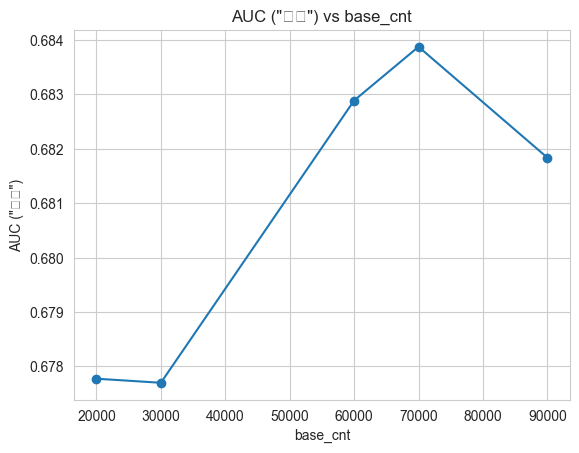

In [56]:
import matplotlib.pyplot as plt

mean_auc = []
base_cnts = []
for base_cnt in train_res_df.columns.levels[0]:
    try:
        auc_value = train_res_df[base_cnt]['AUC'].iloc[-1]
        mean_auc.append(auc_value)
        base_cnts.append(base_cnt)
    except Exception as e:
        continue

plt.figure()
plt.plot(base_cnts, mean_auc, marker='o')
plt.xlabel('base_cnt')
plt.ylabel('AUC ("均值")')
plt.title('AUC ("均值") vs base_cnt')
plt.show()

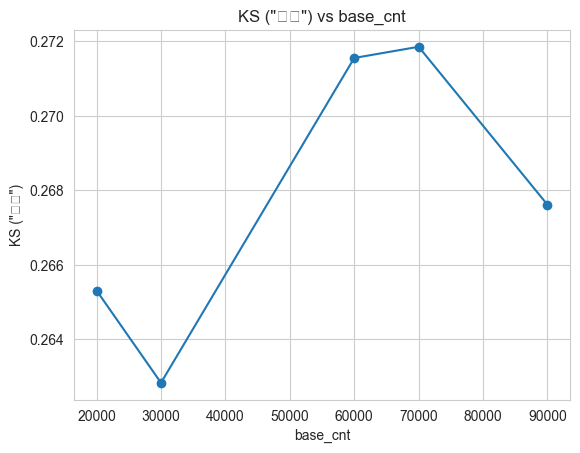

In [ ]:
import matplotlib.pyplot as plt

mean_auc = []
base_cnts = []
for base_cnt in train_res_df.columns.levels[0]:
    try:
        auc_value = train_res_df[base_cnt]['KS'].iloc[-1]
        mean_auc.append(auc_value)
        base_cnts.append(base_cnt)
    except Exception as e:
        continue

plt.figure()
plt.plot(base_cnts, mean_auc, marker='o')
plt.xlabel('base_cnt')
plt.ylabel('KS ("均值")')
plt.title('KS ("均值") vs base_cnt')
plt.show()


## 不同的bad_rate

In [58]:
bad_rate_test = [0.02, 0.05, 0.06, 0.07, 0.10]
params1 = {'objective': 'binary',
'metric': ['auc'],
'boosting_type': 'gbdt',
'learning_rate': 0.046,
'max_depth': 4,
'iterations': 150,
'num_leaves':31,
'min_child_weight': 25,
'feature_fraction': 0.6,
'subsample': 0.8,
'seed': 2078,
'reg_lambda': 2,
'reg_alpha': 2,
'nthread': 12,
'bagging_freq': 11,
'verbose_eval': 300,   
'max_cat_threshold':12, 
'max_bin':183,

'verbose':-2}

In [60]:
cfg = {
    'train_c_19':{'cnt':15000},
    '2-ensemble_c_15':{'cnt':10000}
      }

train_res_df_dict = {}
oos_res_df_dict = {}

for bad_rate in bad_rate_test:
    df_train = balance_df_weight(df_train, 
                           gp_col=gp_col, 
                           label_col=target, 
                           base_cnt=70000, 
                           base_rate=bad_rate, 
                           cfg=cfg)
    print(f"weight_min = {df_train['weight'].min()}, weight_max = {df_train['weight'].max()}")
    df_train = df_train.sample(frac=1, random_state=54533).reset_index(drop=True)
    x_train, x_test, _, _ = train_test_split(df_train, df_train[target], test_size=0.2, random_state=67749)
    x_train = x_train.reset_index(drop=True)
    x_test = x_test.reset_index(drop=True)

    lgb_model = lgb.LGBMClassifier(**params1)
    lgb_model.fit(x_train[feature_cols],x_train['flag'],sample_weight=x_train['weight'])
    df_train['prob_high_hidd+v4'] = lgb_model.predict_proba(df_train[feature_cols])[:, 1]
    df_feas_all['prob_high_hidd+v4'] = lgb_model.predict_proba(df_feas_all[feature_cols])[:, 1]

    """    
    model = mdl.ModelApply.model_fit('LightGBM', x_train[feas], x_train[target], 
                                      None, None, x_train['weight'], params1, ini_model=None)
    feas = mdl.ModelApply.get_model_features(model)
    df_train["pred_prob"]  = np.where(df_train[feas].isnull().all(axis=1), np.nan, mdl.ModelApply.model_predict(df_train[feas], model))
    oos["pred_prob"] = np.where(oos[feas].isnull().all(axis=1), np.nan, mdl.ModelApply.model_predict(oos[feas], model))
    """


    proba_col = 'prob_high_hidd+v4'

    model_perf = ModelDeliveryReport(df_train,target,proba_col,'apply_date',gp_col)
    model_perf_df = model_perf.generate_model_performance()
    # model_perf_df 转成数值
    model_perf_df = model_perf_df.apply(pd.to_numeric, errors='ignore')


    # global_bins = np.quantile(df[proba_col].dropna(), quantiles)
    """model_perf = modelmon.ModelPerf.proba_performance_by_group(df_train[~df_train['partner_name'].isin(['天津银行','辉煌融资租赁','数禾科技'])].reset_index(drop=True), 
                                                              gp_col, target_col, proba_col, quantiles, global_bins)"""
    row_mean = model_perf_df.iloc[1:, 5:8].mean(axis=0)
    row_mean = pd.concat([pd.Series({'group': '均值', model_perf_df.columns[1]: None}), row_mean])
    model_perf = pd.concat([model_perf_df, row_mean.to_frame().T], ignore_index=True)
    train_res_df_dict[bad_rate] = model_perf
    """
    model_perf = modelmon.ModelPerf.proba_performance_by_group(oos, 
                                                              gp_col, target_col, proba_col, quantiles, global_bins)
    row_mean = model_perf.iloc[:, 3:].mean(axis=0)
    row_mean = pd.concat([pd.Series({'group': '均值', model_perf.columns[1]: None}), row_mean])
    model_perf = pd.concat([model_perf, row_mean.to_frame().T], ignore_index=True)
    oos_res_df_dict[base_cnt] = model_perf
    
    """

weight_min = 0.2600297176820208, weight_max = 6.044052863436123
weight_min = 0.650074294205052, weight_max = 9.48509485094851
weight_min = 0.771123872026251, weight_max = 11.382113821138212
weight_min = 0.7629204265791631, weight_max = 13.279132791327916
weight_min = 0.7383100902379, weight_max = 18.97018970189702


In [61]:
train_res_df = pd.concat(list(train_res_df_dict.values()), axis=1, keys=list(train_res_df_dict.keys()))
train_res_df

0.02                                                        \
           样本类型    Good      Bad     Total Bad_Rate      KS       AUC   
0           all  304387  15823.0  320210.0   0.0494  0.2169    0.6559   
1  1-train_c_14   58519   2082.0   60601.0   0.0344  0.2122    0.6526   
2  1-train_c_12   85330   5384.0   90714.0   0.0594  0.1532    0.6078   
3  1-train_c_10   43880   2329.0   46209.0   0.0504  0.2131    0.6409   
4  1-train_c_18   28616   1134.0   29750.0   0.0381   0.337    0.7263   
5  1-train_c_21   25667   1668.0   27335.0   0.0610  0.1928    0.6396   
6  1-train_c_19   11350    369.0   11719.0   0.0315  0.3985    0.7643   
7  1-train_c_16   28512   1911.0   30423.0   0.0628  0.2623    0.6742   
8  1-train_c_20   22513    946.0   23459.0   0.0403  0.3453     0.734   
9           NaN    None      NaN       NaN      NaN  0.2643  0.679963   

                         ...          0.10                             \
  TOP10_lift  PSI group  ...          样本类型    Good      Bad     Total   
0     2.3238  0.0   NaN  ...           all  304387  15823.0  320210.0   
1     2.3343  0.0   NaN  ...  1-train_c_12   85330   5384.0   90714.0   
2     1.8424  0.0   NaN  ...  1-train_c_18   28616   1134.0   29750.0   
3     2.0996  0.0   NaN  ...  1-train_c_14   58519   2082.0   60601.0   
4     3.2099  0.0   NaN  ...  1-train_c_21   25667   1668.0   27335.0   
5     2.1219  0.0   NaN  ...  1-train_c_19   11350    369.0   11719.0   
6     3.5227  0.0   NaN  ...  1-train_c_16   28512   1911.0   30423.0   
7     2.3961  0.0   NaN  ...  1-train_c_10   43880   2329.0   46209.0   
8     3.3931  0.0   NaN  ...  1-train_c_20   22513    946.0   23459.0   
9      2.615  NaN    均值  ...           NaN    None      NaN       NaN   

                                                     
  Bad_Rate        KS      AUC TOP10_lift  PSI group  
0   0.0494     0.218   0.6582     2.3283  0.0   NaN  
1   0.0594    0.1549   0.6082     1.8405  0.0   NaN  
2   0.0381    0.3401   0.7356     3.1658  0.0   NaN  
3   0.0344    0.2196   0.6522     2.4448  0.0   NaN  
4   0.0610    0.1955   0.6381     2.1039  0.0   NaN  
5   0.0315    0.3961   0.7732     3.5769  0.0   NaN  
6   0.0628    0.2549   0.6727      2.417  0.0   NaN  
7   0.0504    0.2162    0.645     2.1854  0.0   NaN  
8   0.0403    0.3638   0.7474     3.2028  0.0   NaN  
9      NaN  0.267638  0.68405   2.617138  NaN    均值  

[10 rows x 50 columns]

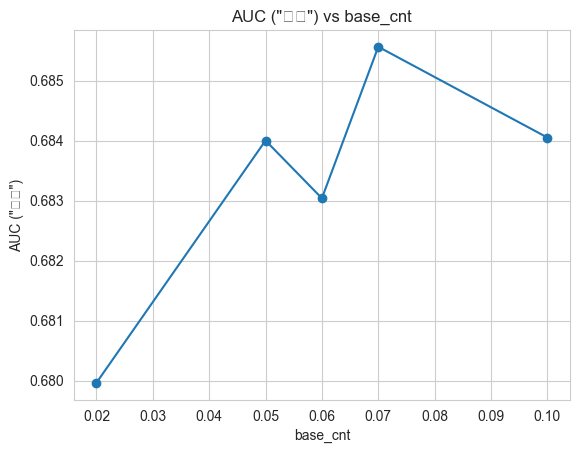

In [62]:
import matplotlib.pyplot as plt

mean_auc = []
base_cnts = []
for base_cnt in train_res_df.columns.levels[0]:
    try:
        auc_value = train_res_df[base_cnt]['AUC'].iloc[-1]
        mean_auc.append(auc_value)
        base_cnts.append(base_cnt)
    except Exception as e:
        continue

plt.figure()
plt.plot(base_cnts, mean_auc, marker='o')
plt.xlabel('base_cnt')
plt.ylabel('AUC ("均值")')
plt.title('AUC ("均值") vs base_cnt')
plt.show()

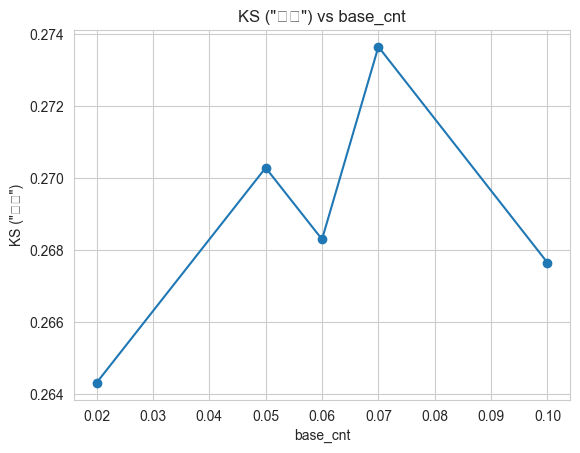

In [63]:
import matplotlib.pyplot as plt

mean_auc = []
base_cnts = []
for base_cnt in train_res_df.columns.levels[0]:
    try:
        auc_value = train_res_df[base_cnt]['KS'].iloc[-1]
        mean_auc.append(auc_value)
        base_cnts.append(base_cnt)
    except Exception as e:
        continue

plt.figure()
plt.plot(base_cnts, mean_auc, marker='o')
plt.xlabel('base_cnt')
plt.ylabel('KS ("均值")')
plt.title('KS ("均值") vs base_cnt')
plt.show()


# add weight

In [34]:
gp_col = 'part_sample_code'
target = 'flag'
df_feas_all.groupby([gp_col]).agg({target:[len,sum,'mean']})

flag                   
                     len      sum      mean
part_sample_code                           
1-train_c_10       46209   2329.0  0.050401
1-train_c_12       90714   5384.0  0.059351
1-train_c_14       60601   2082.0  0.034356
1-train_c_16       30423   1911.0  0.062814
1-train_c_18       29750   1134.0  0.038118
1-train_c_19       11719    369.0  0.031487
1-train_c_20       23459    946.0  0.040326
1-train_c_21       27335   1668.0  0.061021
2-ensemble_b_6    244934   7104.0  0.029004
2-ensemble_c_11    29533   1747.0  0.059154
2-ensemble_c_15     4515    185.0  0.040975
2-ensemble_c_17    17580    902.0  0.051308
3-oos_c_23         61611   9949.0  0.161481
3-oos_c_24         33520   2828.0  0.084368
3-oos_c_25         24729   3014.0  0.121881
3-oos_c_26         50782  12700.0  0.250089
3-oos_c_27         25554   2956.0  0.115677
3-oos_c_28         23015   4507.0  0.195829
3-oos_c_32        152657   8942.0  0.058576
3-oos_c_33         98385  17733.0  0.180241

In [64]:

print(f'加入weight前df的shape为{df_train.shape}')
df_train = balance_df_weight(df_train, 
                           gp_col=gp_col, 
                           label_col=target, 
                           base_cnt=70000, 
                           base_rate=0.07, 
                           cfg=cfg)

print(f'加入weight后df的shape为{df_train.shape}')
print(f"weight_min = {df_train['weight'].min()}, weight_max = {df_train['weight'].max()}")

加入weight前df的shape为(320210, 357)
加入weight后df的shape为(320210, 357)
weight_min = 0.7629204265791631, weight_max = 13.279132791327916


In [66]:
df_train.head()

,serie_no,test_id,apply_date,hce1,hce10,hce11,hce12,hce13,hce14,hce15,...,partner_name,pric_type_code,high_sample_type,pric_type_desc,蜜蜂分_高利率版5_2_proba,蜜蜂分_高利率版6_2_proba,蜜蜂分_高利率版7_2_proba,part_sample_code,weight,prob_high_hidd+v4
0,327986,3731093,2024-10-01,1.0,1.0,23.0,18.0,1.0,21.0,22.0,...,恒昌客群C,c,1-train,高利率,0.044503,0.066054,0.021495,1-train_c_12,0.762920,0.042869
1,17453,3767986,2024-08-12,21.0,1.0,16.0,1.0,21.0,14.0,11.0,...,恒昌客群C,c,1-train,高利率,0.068404,0.158681,0.086447,1-train_c_12,0.762920,0.077776
2,71239,4296148,2024-08-26,25.0,1.0,1.0,1.0,26.0,1.0,1.0,...,lexin_type1,c,1-train,高利率,0.087111,0.135240,0.089128,1-train_c_18,4.320988,0.251267
3,291354,3689651,2024-09-13,22.0,1.0,9.0,1.0,23.0,12.0,6.0,...,恒昌客群C,c,1-train,高利率,0.074621,0.137444,0.079078,1-train_c_12,0.762920,0.076357
4,408133,3994503,2024-08-25,1.0,1.0,18.0,9.0,1.0,15.0,14.0,...,众安小贷复贷常规,c,1-train,高利率,0.066401,0.150160,0.078970,1-train_c_14,1.112459,0.120520


In [68]:
tuner = AntiOverfittingTuner(lgb.LGBMClassifier,'lgb')
params_grid_lgb = tuner.optimize_anti_overfitting(
    df_train[feature_cols+['weight']],
    df_train['flag'],
    weight_col = 'weight',
    n_trials=30
)

  0%|          | 0/30 [00:00<?, ?it/s]

In [69]:
pd.DataFrame(params_grid_lgb['performance_history']).to_csv('output_weight/params_log_lgb.csv',index=False)

In [71]:
params_grid_lgb = pd.read_csv('output_weight/params_log_lgb.csv')
params_grid_lgb = params_grid_lgb[params_grid_lgb['is_overfitting']==False]
params_grid_lgb

,trial,params,train_score,val_score,final_score,train_auc,val_auc,train_ks,val_ks,auc_gap,ks_gap,is_overfitting,total_penalty,train_score_std,val_score_std,train_auc_std,val_auc_std
0,0,"{'boosting_type': 'dart', 'num_leaves': 43, 'm...",0.655027,0.637262,0.637262,0.655027,0.637262,0.212048,0.193361,0.017765,0.018687,False,0.0,0.001085,0.004218,0.001085,0.004218
16,16,"{'boosting_type': 'dart', 'num_leaves': 94, 'm...",0.633664,0.630068,0.630068,0.633664,0.630068,0.184389,0.184791,0.003596,0.000403,False,0.0,0.001227,0.004524,0.001227,0.004524
18,18,"{'boosting_type': 'goss', 'num_leaves': 31, 'm...",0.654524,0.637400,0.637400,0.654524,0.637400,0.212604,0.194385,0.017124,0.018219,False,0.0,0.000687,0.003955,0.000687,0.003955
20,20,"{'boosting_type': 'goss', 'num_leaves': 5, 'ma...",0.637402,0.633021,0.633021,0.637402,0.633021,0.189529,0.187160,0.004380,0.002369,False,0.0,0.000973,0.004125,0.000973,0.004125
22,22,"{'boosting_type': 'goss', 'num_leaves': 39, 'm...",0.660897,0.638644,0.638644,0.660897,0.638644,0.221236,0.196401,0.022253,0.024835,False,0.0,0.000481,0.003874,0.000481,0.003874
23,23,"{'boosting_type': 'goss', 'num_leaves': 7, 'ma...",0.635837,0.631843,0.631843,0.635837,0.631843,0.185985,0.186749,0.003994,0.000765,False,0.0,0.001071,0.004077,0.001071,0.004077
27,27,"{'boosting_type': 'gbdt', 'num_leaves': 23, 'm...",0.649762,0.636832,0.636832,0.649762,0.636832,0.204316,0.192829,0.012929,0.011487,False,0.0,0.000950,0.004016,0.000950,0.004016
28,28,"{'boosting_type': 'goss', 'num_leaves': 31, 'm...",0.649695,0.635193,0.635193,0.649695,0.635193,0.206695,0.189944,0.014502,0.016751,False,0.0,0.000502,0.003982,0.000502,0.003982


In [75]:
import ast
candidate_params = params_grid_lgb['params'].to_list()
candidate_params = [ast.literal_eval(s) for s in candidate_params]
candidate_params

[{'boosting_type': 'dart',
  'num_leaves': 43,
  'max_depth': 6,
  'learning_rate': 0.0024345423962016913,
  'n_estimators': 500,
  'subsample_for_bin': 179927,
  'min_split_gain': 0.6011150117432088,
  'min_child_weight': 0.6796578090758157,
  'min_child_samples': 22,
  'colsample_bytree': 0.939468448256698,
  'reg_alpha': 2.587041577736259,
  'reg_lambda': 0.0013354142153961545,
  'random_state': 42,
  'n_jobs': -1,
  'verbosity': -1,
  'objective': 'binary',
  'metric': 'binary_logloss',
  'is_unbalance': False,
  'subsample': 0.7064847850358382,
  'subsample_freq': 4,
  'drop_rate': 0.22165305913463673,
  'max_drop': 15,
  'skip_drop': 0.6118528947223795,
  'xgboost_dart_mode': False},
 {'boosting_type': 'dart',
  'num_leaves': 94,
  'max_depth': 8,
  'learning_rate': 0.002256354644027594,
  'n_estimators': 535,
  'subsample_for_bin': 189709,
  'min_split_gain': 0.829585637233477,
  'min_child_weight': 0.21864396421302087,
  'min_child_samples': 65,
  'colsample_bytree': 0.85840314

In [85]:
candidate_params[-2]

{'boosting_type': 'gbdt',
 'num_leaves': 23,
 'max_depth': 6,
 'learning_rate': 0.0014685872341687913,
 'n_estimators': 500,
 'subsample_for_bin': 186604,
 'min_split_gain': 0.7289845211124466,
 'min_child_weight': 0.01873037136475726,
 'min_child_samples': 74,
 'colsample_bytree': 0.6307754540748558,
 'reg_alpha': 0.016128116520710264,
 'reg_lambda': 0.000387795919896329,
 'random_state': 42,
 'n_jobs': -1,
 'verbosity': -1,
 'objective': 'binary',
 'metric': 'binary_logloss',
 'is_unbalance': False,
 'subsample': 0.829282394672235,
 'subsample_freq': 6}

In [81]:
model_lgb = lgb.LGBMClassifier(**candidate_params[-2])
model_lgb.fit(
    df_train[feature_cols],
    df_train['flag'],
    sample_weight = df_train['weight'],
)
joblib.dump(model_lgb,'models_weight/lgb.pkl')

['models_weight/lgb.pkl']

In [82]:
df_feas_all['lgb_weight'] = model_lgb.predict_proba(df_feas_all[feature_cols])[:,1]

In [84]:
reporter = ModelDeliveryReport(df_feas_all,target,'lgb_weight','apply_date',gp_col)
model_perf_df = reporter.generate_full_report(
            features=feature_cols,
            save_path='output_weight/perf_lgb.xlsx',
            model=model_lgb
        )

✓ 样本情况统计完成
✓ 模型效果分析完成
✓ 模型效果分箱分析完成
✓ 评估指标报告生成完成
✓ TOP10变量有效性分析完成
✓ 变量有效性按月拆分分析完成
✓ TOP10变量稳定性分析完成
✓ 单特征时间分布分析完成
✓ 模型分表现分析完成
✓ 报告已保存至: output_weight/perf_lgb.xlsx


# 融合6-2

In [53]:
def LogitTransformation(prob):
    if 0<prob<1:
        return np.log(prob/(1-prob))
    else:
        return 0


def Prob2Score(prob, basePoint, PDO):
    y = np.log(prob/(1-prob))
    return basePoint+PDO/np.log(2)*(-y)


def AdjustScore(prob, min_score, max_score, basePoint, PDO):
    if prob <= 0 or prob >= 1:
        return 0

    score = Prob2Score(prob, basePoint, PDO)
    if score < min_score:
        score = min_score
    if score > max_score:
        score = max_score

    score_new = int(round((score-min_score)*600.0/(max_score - min_score) + 300,0))
    if score_new < 300:
        score_new = 300
    if score_new > 900:
        score_new = 900
    return int(score_new)
def get_valid_prob(x):

    if x <= 0 or x >= 1:
        y = 0
    else:
        y = 1
    return y


In [88]:
sub_probs = ['蜜蜂分_高利率版6_2_proba','lgb_weight']
feas = []
for fea in sub_probs:
    df_feas_all[f'{fea}_fill'] = df_feas_all[fea].fillna(0)
    df_feas_all[f'{fea}_valid'] = df_feas_all[f'{fea}_fill'].apply(get_valid_prob)
    df_feas_all[f'{fea}_trans'] = df_feas_all[f'{fea}_fill'].apply(LogitTransformation)
    feas.append(f'{fea}_trans')
    feas.append(f'{fea}_valid')

In [89]:
df_feas_all['high_sample_type'].value_counts()

high_sample_type
3-oos         470253
1-train       320210
2-ensemble    296562
Name: count, dtype: int64

In [91]:
tuner = AntiOverfittingTuner(LogisticRegression,'lr')
params_grid_lr = tuner.optimize_anti_overfitting(
    df_feas_all[df_feas_all['high_sample_type']=='2-ensemble'][feas],
    df_feas_all[df_feas_all['high_sample_type']=='2-ensemble']['flag'],
    n_trials=30
)

  0%|          | 0/30 [00:00<?, ?it/s]

In [92]:
pd.DataFrame(params_grid_lr['performance_history']).to_csv('output_weight/lr_params_log_weight.csv',index=False)

In [ ]:
params_grid_lr = pd.read_csv('output_weight/lr_params_log_weight_ens.csv')
params_grid_lr = params_grid_lr[params_grid_lr['is_overfitting']==False]
params_grid_lr

,trial,params,train_score,val_score,final_score,train_auc,val_auc,train_ks,val_ks,auc_gap,ks_gap,is_overfitting,total_penalty,train_score_std,val_score_std,train_auc_std,val_auc_std
0,0,"{'C': 15.741890047456641, 'penalty': 'l1', 'so...",0.663588,0.663569,0.663569,0.663588,0.663569,0.233421,0.236789,0.000019,0.003368,False,0.0,0.001778,0.007189,0.001778,0.007189
1,3,"{'C': 0.0015777663630582469, 'penalty': None, ...",0.663588,0.663568,0.663568,0.663588,0.663568,0.233417,0.236506,0.000021,0.003089,False,0.0,0.001778,0.007191,0.001778,0.007191
2,5,"{'C': 0.0005397956855996448, 'penalty': 'elast...",0.644357,0.644372,0.644372,0.644357,0.644372,0.221483,0.224588,0.000015,0.003105,False,0.0,0.001585,0.005933,0.001585,0.005933
3,10,"{'C': 65.6481761175346, 'penalty': 'l1', 'solv...",0.663589,0.663569,0.663569,0.663589,0.663569,0.233419,0.236665,0.000019,0.003245,False,0.0,0.001779,0.007189,0.001779,0.007189
4,11,"{'C': 83.67826428540977, 'penalty': 'l1', 'sol...",0.663589,0.663569,0.663569,0.663589,0.663569,0.233419,0.236824,0.000019,0.003405,False,0.0,0.001779,0.007189,0.001779,0.007189
5,12,"{'C': 94.42207016006594, 'penalty': 'l1', 'sol...",0.663589,0.663569,0.663569,0.663589,0.663569,0.233419,0.236824,0.000019,0.003405,False,0.0,0.001779,0.007189,0.001779,0.007189
6,13,"{'C': 1.7206300727024646, 'penalty': 'l1', 'so...",0.663580,0.663562,0.663562,0.663580,0.663562,0.233368,0.236380,0.000018,0.003012,False,0.0,0.001778,0.007186,0.001778,0.007186
7,15,"{'C': 0.20519059010204016, 'penalty': 'l2', 's...",0.663439,0.663434,0.663434,0.663439,0.663434,0.233013,0.236831,0.000005,0.003818,False,0.0,0.001770,0.007126,0.001770,0.007126
8,16,"{'C': 55.76242278032358, 'penalty': 'l1', 'sol...",0.663589,0.663569,0.663569,0.663589,0.663569,0.233420,0.236668,0.000019,0.003248,False,0.0,0.001779,0.007189,0.001779,0.007189
9,17,"{'C': 1.947856459923636, 'penalty': 'l1', 'sol...",0.663581,0.663563,0.663563,0.663581,0.663563,0.233381,0.236391,0.000018,0.003010,False,0.0,0.001778,0.007186,0.001778,0.007186


In [94]:
import ast
candidate_params = params_grid_lr['params'].to_list()
candidate_params = [ast.literal_eval(s) for s in candidate_params]

In [96]:
model_lr = LogisticRegression(**candidate_params[0])
model_lr.fit(
    df_feas_all[df_feas_all['high_sample_type']=='2-ensemble'][feas],
    df_feas_all[df_feas_all['high_sample_type']=='2-ensemble']['flag'],
)
joblib.dump(model_lr,'models_weight/lr_weight_ens.pkl')

['models_weight/lr_weight_ens.pkl']

In [99]:
df_feas_all['lr_weight_ens'] = model_lr.predict_proba(df_feas_all[feas])[:,1]

In [100]:
model_perf = ModelDeliveryReport(df_feas_all,'flag',['lr_weight_ens','蜜蜂分_高利率版7_2_proba'],'apply_date','part_sample_code')
model_perf_df = model_perf.generate_model_performance()
model_perf_df

多分数模式(intersection)：过滤掉 517946 行存在缺失分数的样本，剩余 569079 行


,样本类型,Good,Bad,Total,Bad_Rate,KS_lr_weight_ens,AUC_lr_weight_ens,TOP10_lift_lr_weight_ens,PSI_lr_weight_ens,KS_蜜蜂分_高利率版7_2_proba,AUC_蜜蜂分_高利率版7_2_proba,TOP10_lift_蜜蜂分_高利率版7_2_proba,PSI_蜜蜂分_高利率版7_2_proba
0,all,514556,54523,569079,0.0958,0.1814,0.6277,1.8748,0.0000,0.1635,0.6129,1.7136,0.0000
1,1-train_c_10,43868,2326,46194,0.0504,0.2325,0.6583,2.3557,0.0000,0.2047,0.6413,2.1020,0.0000
2,2-ensemble_c_11,27783,1747,29530,0.0592,0.1795,0.6267,2.0721,0.0000,0.2188,0.6416,2.0778,0.0000
3,1-train_c_12,85326,5384,90710,0.0594,0.1767,0.6230,1.9484,0.0000,0.1570,0.6056,1.7218,0.0000
4,1-train_c_14,58371,2076,60447,0.0343,0.2433,0.6686,2.6203,0.0000,0.2162,0.6440,2.2350,0.0000
5,2-ensemble_c_15,4322,185,4507,0.0410,0.2699,0.6804,2.4308,0.0000,0.3201,0.7090,2.7009,0.0000
6,1-train_c_16,28287,1901,30188,0.0630,0.2712,0.6824,2.4459,0.0000,0.2112,0.6421,1.9988,0.0000
7,2-ensemble_c_17,16622,898,17520,0.0513,0.3425,0.7294,3.1626,0.0000,0.3609,0.7450,3.5746,0.0000
8,1-train_c_18,18222,1110,19332,0.0574,0.2990,0.6989,3.0258,0.0000,0.1769,0.6201,1.8551,0.0000
9,1-train_c_19,11323,363,11686,0.0311,0.3295,0.7224,3.3597,0.0000,0.1628,0.6024,1.8726,0.0000


In [101]:
model_perf_df.to_excel('output_weight/perf_vs_g72_weight_ens.xlsx')

# 采样2-ensemble_b_6

In [3]:
df_feas_all = pd.read_csv('/Users/mayongzhi/Job/Job_xyd/code/测试V4+embeding/df_feas_all_with_prob.csv')
df_feas_all.head()

,serie_no,test_id,apply_date,hce1,hce10,hce11,hce12,hce13,hce14,hce15,...,蜜蜂分_高利率版6_2_proba_trans,prob_lgb_fill,prob_lgb_valid,prob_lgb_trans,lr_weight_ens_sam_b6,score_test,fit_score,fit_score_lgb,lr_score_test,fit_score_lr
0,1,3600806,2024-08-21,22.0,1.0,1.0,1.0,26.0,1.0,1.0,...,-2.051427,0.331276,1,-0.702421,0.040708,901.337988,833,833,1255.857561,639
1,2,3600807,2024-08-21,1.0,1.0,21.0,13.0,1.0,17.0,20.0,...,-1.836925,0.330173,1,-0.707404,0.046502,902.056771,839,839,1235.786635,627
2,3,3600808,2024-08-21,20.0,1.0,1.0,1.0,21.0,1.0,5.0,...,-1.906917,0.327114,1,-0.721266,0.038110,904.056741,854,854,1265.763076,645
3,4,3600809,2024-08-21,26.0,1.0,1.0,1.0,26.0,1.0,1.0,...,-1.505900,0.354103,1,-0.601051,0.166547,886.713321,721,721,1032.317341,507
4,5,3600810,2024-08-21,21.0,1.0,1.0,1.0,26.0,1.0,1.0,...,-2.272080,0.330798,1,-0.704576,0.032952,901.648805,836,836,1287.514971,657


In [4]:
df_feas_all.shape

(1087025, 371)

In [6]:
df_feas_all.columns[-30:]

Index(['hxe79', 'hxe8', 'hxe80', 'hxe9', 'flag', 'partner_code',
       'partner_name', 'pric_type_code', 'high_sample_type', 'pric_type_desc',
       '蜜蜂分_高利率版5_2_proba', '蜜蜂分_高利率版6_2_proba', '蜜蜂分_高利率版7_2_proba',
       'part_sample_code', 'prob_lgb_all_features', 'prob_lgb_no_zero',
       'prob_diff_no_zero_minus_all', 'prob_lgb', '蜜蜂分_高利率版6_2_proba_fill',
       '蜜蜂分_高利率版6_2_proba_valid', '蜜蜂分_高利率版6_2_proba_trans', 'prob_lgb_fill',
       'prob_lgb_valid', 'prob_lgb_trans', 'lr_weight_ens_sam_b6',
       'score_test', 'fit_score', 'fit_score_lgb', 'lr_score_test',
       'fit_score_lr'],
      dtype='object')

In [9]:
ym_feas = df_feas_all.columns[3:-26]
ym_feas

Index(['hce1', 'hce10', 'hce11', 'hce12', 'hce13', 'hce14', 'hce15', 'hce16',
       'hce17', 'hce18',
       ...
       'hxe73', 'hxe74', 'hxe75', 'hxe76', 'hxe77', 'hxe78', 'hxe79', 'hxe8',
       'hxe80', 'hxe9'],
      dtype='object', length=342)

In [10]:
# df_feas_all 的 ym_feas全为空时,prob_lgb赋值为0
df_feas_all['prob_lgb'] = df_feas_all.apply(lambda x: 0 if x[ym_feas].isnull().all() else x['prob_lgb'], axis=1)

In [12]:
def LogitTransformation(prob):
    if 0<prob<1:
        return np.log(prob/(1-prob))
    else:
        return 0


def Prob2Score(prob, basePoint, PDO):
    y = np.log(prob/(1-prob))
    return basePoint+PDO/np.log(2)*(-y)


def AdjustScore(prob, min_score, max_score, basePoint, PDO):
    if prob <= 0 or prob >= 1:
        return 0

    score = Prob2Score(prob, basePoint, PDO)
    if score < min_score:
        score = min_score
    if score > max_score:
        score = max_score

    score_new = int(round((score-min_score)*600.0/(max_score - min_score) + 300,0))
    if score_new < 300:
        score_new = 300
    if score_new > 900:
        score_new = 900
    return int(score_new)
def get_valid_prob(x):

    if x <= 0 or x >= 1:
        y = 0
    else:
        y = 1
    return y


In [13]:
sub_probs = ['蜜蜂分_高利率版6_2_proba','prob_lgb']
feas = []
for fea in sub_probs:
    df_feas_all[f'{fea}_fill'] = df_feas_all[fea].fillna(0)
    df_feas_all[f'{fea}_valid'] = df_feas_all[f'{fea}_fill'].apply(get_valid_prob)
    df_feas_all[f'{fea}_trans'] = df_feas_all[f'{fea}_fill'].apply(LogitTransformation)
    feas.append(f'{fea}_trans')
    feas.append(f'{fea}_valid')

In [14]:
feas

['蜜蜂分_高利率版6_2_proba_trans',
 '蜜蜂分_高利率版6_2_proba_valid',
 'prob_lgb_trans',
 'prob_lgb_valid']

In [15]:
# 对于df_feas_all中 part_sample_code=='2-ensemble_b_6'，坏样本全保留，总样本保留90000

df_ens_b6_sample = df_feas_all[df_feas_all['part_sample_code']=='2-ensemble_b_6'].copy()
df_ens_b6_sample = df_ens_b6_sample.sort_values('apply_date').reset_index(drop=True)
df_ens_b6_bad = df_ens_b6_sample[df_ens_b6_sample['flag']==1]
df_ens_b6_good = df_ens_b6_sample[df_ens_b6_sample['flag']==0].sample(n=90000-len(df_ens_b6_bad), random_state=9999)
df_ens_b6 = pd.concat([df_ens_b6_bad, df_ens_b6_good], ignore_index=True)
df_ens_b6 = df_ens_b6.sample(frac=1, random_state=9999).reset_index(drop=True)
df_ens_b6['flag'].value_counts()

flag
0.0    82896
1.0     7104
Name: count, dtype: int64

In [16]:
df_feas_all['high_sample_type'].value_counts()

high_sample_type
3-oos         470253
1-train       320210
2-ensemble    296562
Name: count, dtype: int64

In [17]:
df_train4lr = df_feas_all[(df_feas_all['part_sample_code']!='2-ensemble_b_6') & (df_feas_all['high_sample_type'].isin(['1-train','2-ensemble']))].copy()
df_train4lr = pd.concat([df_train4lr, df_ens_b6], ignore_index=True)
df_train4lr.shape

(461838, 371)

In [ ]:
df_train4lr

In [18]:
df_train4lr.head()

,serie_no,test_id,apply_date,hce1,hce10,hce11,hce12,hce13,hce14,hce15,...,蜜蜂分_高利率版6_2_proba_trans,prob_lgb_fill,prob_lgb_valid,prob_lgb_trans,lr_weight_ens_sam_b6,score_test,fit_score,fit_score_lgb,lr_score_test,fit_score_lr
0,1,3600806,2024-08-21,22.0,1.0,1.0,1.0,26.0,1.0,1.0,...,-2.051427,0.331276,1,-0.702421,0.040708,901.337988,833,833,1255.857561,639
1,2,3600807,2024-08-21,1.0,1.0,21.0,13.0,1.0,17.0,20.0,...,-1.836925,0.330173,1,-0.707404,0.046502,902.056771,839,839,1235.786635,627
2,3,3600808,2024-08-21,20.0,1.0,1.0,1.0,21.0,1.0,5.0,...,-1.906917,0.327114,1,-0.721266,0.038110,904.056741,854,854,1265.763076,645
3,4,3600809,2024-08-21,26.0,1.0,1.0,1.0,26.0,1.0,1.0,...,-1.505900,0.354103,1,-0.601051,0.166547,886.713321,721,721,1032.317341,507
4,5,3600810,2024-08-21,21.0,1.0,1.0,1.0,26.0,1.0,1.0,...,-2.272080,0.330798,1,-0.704576,0.032952,901.648805,836,836,1287.514971,657


In [19]:
df_train4lr[feas]

,蜜蜂分_高利率版6_2_proba_trans,蜜蜂分_高利率版6_2_proba_valid,prob_lgb_trans,prob_lgb_valid
0,-2.051427,1,-0.702421,1
1,-1.836925,1,-0.707404,1
2,-1.906917,1,-0.721266,1
3,-1.505900,1,-0.601051,1
4,-2.272080,1,-0.704576,1
...,...,...,...,...
461833,0.000000,0,-0.731119,1
461834,0.000000,0,-0.717257,1
461835,0.000000,0,-0.695323,1
461836,0.000000,0,-0.748256,1


In [20]:
tuner = AntiOverfittingTuner(LogisticRegression,'lr')
params_grid_lr = tuner.optimize_anti_overfitting(
    df_train4lr[feas],
    df_train4lr['flag'],
    n_trials=30
)

  0%|          | 0/30 [00:00<?, ?it/s]

In [21]:
pd.DataFrame(params_grid_lr['performance_history']).to_csv('V1.1_output/lr_params_log_weight_sam_b6.csv',index=False)

In [22]:
params_grid_lr = pd.read_csv('V1.1_output/lr_params_log_weight_sam_b6.csv')
params_grid_lr = params_grid_lr[params_grid_lr['is_overfitting']==False]
params_grid_lr

,trial,params,train_score,val_score,final_score,train_auc,val_auc,train_ks,val_ks,auc_gap,ks_gap,is_overfitting,total_penalty,train_score_std,val_score_std,train_auc_std,val_auc_std
0,0,"{'C': 15.741890047456641, 'penalty': 'l1', 'so...",0.654622,0.654528,0.654528,0.654622,0.654528,0.220614,0.222382,0.000094,0.001768,False,0.0,0.000582,0.002012,0.000582,0.002012
1,3,"{'C': 0.0015777663630582469, 'penalty': None, ...",0.654623,0.654529,0.654529,0.654623,0.654529,0.220620,0.222371,0.000094,0.001751,False,0.0,0.000582,0.002012,0.000582,0.002012
2,5,"{'C': 0.0005397956855996448, 'penalty': 'elast...",0.591056,0.591009,0.591009,0.591056,0.591009,0.139448,0.141289,0.000048,0.001841,False,0.0,0.000251,0.000881,0.000251,0.000881
3,10,"{'C': 0.000769639183009799, 'penalty': None, '...",0.654623,0.654529,0.654529,0.654623,0.654529,0.220620,0.222371,0.000094,0.001751,False,0.0,0.000582,0.002012,0.000582,0.002012
4,11,"{'C': 0.0005350071576967551, 'penalty': None, ...",0.654623,0.654529,0.654529,0.654623,0.654529,0.220620,0.222371,0.000094,0.001751,False,0.0,0.000582,0.002012,0.000582,0.002012
5,12,"{'C': 0.01009570399417486, 'penalty': None, 's...",0.654623,0.654529,0.654529,0.654623,0.654529,0.220620,0.222371,0.000094,0.001751,False,0.0,0.000582,0.002012,0.000582,0.002012
6,13,"{'C': 0.04254242912496109, 'penalty': None, 's...",0.654623,0.654529,0.654529,0.654623,0.654529,0.220620,0.222371,0.000094,0.001751,False,0.0,0.000582,0.002012,0.000582,0.002012
7,15,"{'C': 0.00010847199548376785, 'penalty': 'l2',...",0.588462,0.588413,0.588413,0.588462,0.588413,0.138005,0.139543,0.000049,0.001538,False,0.0,0.000242,0.000950,0.000242,0.000950
8,16,"{'C': 0.004961338420711863, 'penalty': None, '...",0.654623,0.654529,0.654529,0.654623,0.654529,0.220620,0.222371,0.000094,0.001751,False,0.0,0.000582,0.002012,0.000582,0.002012
9,17,"{'C': 1.1045487630580906, 'penalty': None, 'so...",0.654623,0.654529,0.654529,0.654623,0.654529,0.220620,0.222371,0.000094,0.001751,False,0.0,0.000582,0.002012,0.000582,0.002012


In [23]:
import ast
candidate_params = params_grid_lr['params'].to_list()
candidate_params = [ast.literal_eval(s) for s in candidate_params]

In [25]:
model_lr = LogisticRegression(**candidate_params[0])
model_lr.fit(
    df_train4lr[feas],
    df_train4lr['flag'],
)
joblib.dump(model_lr,'V1.1_output/lr_weight_ens_sam_b6.pkl')

['V1.1_output/lr_weight_ens_sam_b6.pkl']

In [26]:
df_feas_all['lr_weight_ens_sam_b6'] = model_lr.predict_proba(df_feas_all[feas])[:,1]

In [73]:
model_perf = ModelDeliveryReport(df_feas_all,'flag',['lr_weight_ens_sam_b6','蜜蜂分_高利率版7_2_proba'],'apply_date','part_sample_code')
model_perf_df = model_perf.generate_model_performance()
model_perf_df

多分数模式(intersection)：过滤掉 517946 行存在缺失分数的样本，剩余 569079 行


,样本类型,Good,Bad,Total,Bad_Rate,KS_lr_weight_ens_sam_b6,AUC_lr_weight_ens_sam_b6,TOP10_lift_lr_weight_ens_sam_b6,PSI_lr_weight_ens_sam_b6,KS_蜜蜂分_高利率版7_2_proba,AUC_蜜蜂分_高利率版7_2_proba,TOP10_lift_蜜蜂分_高利率版7_2_proba,PSI_蜜蜂分_高利率版7_2_proba
0,all,514556,54523,569079,0.0958,0.1877,0.6306,1.9106,0.0000,0.1635,0.6129,1.7136,0.0000
1,1-train_c_10,43868,2326,46194,0.0504,0.2393,0.6652,2.3557,0.0000,0.2047,0.6413,2.1020,0.0000
2,2-ensemble_c_11,27783,1747,29530,0.0592,0.1818,0.6323,2.1694,0.0000,0.2188,0.6416,2.0778,0.0000
3,1-train_c_12,85326,5384,90710,0.0594,0.1892,0.6319,2.0449,0.0000,0.1570,0.6056,1.7218,0.0000
4,1-train_c_14,58371,2076,60447,0.0343,0.2566,0.6739,2.6685,0.0000,0.2162,0.6440,2.2350,0.0000
5,2-ensemble_c_15,4322,185,4507,0.0410,0.2764,0.6871,2.6469,0.0000,0.3201,0.7090,2.7009,0.0000
6,1-train_c_16,28287,1901,30188,0.0630,0.2698,0.6829,2.5406,0.0000,0.2112,0.6421,1.9988,0.0000
7,2-ensemble_c_17,16622,898,17520,0.0513,0.3403,0.7310,3.0846,0.0000,0.3609,0.7450,3.5746,0.0000
8,1-train_c_18,18222,1110,19332,0.0574,0.2620,0.6768,2.7646,0.0000,0.1769,0.6201,1.8551,0.0000
9,1-train_c_19,11323,363,11686,0.0311,0.2482,0.6575,2.2306,0.0000,0.1628,0.6024,1.8726,0.0000


In [74]:
model_perf_df.to_excel('V1.1_output/perf_vs_g72_weight_ens_sam_b6.xlsx')

# 分值转换

In [27]:
import math
import matplotlib.pyplot as plt
def Prob2Score(prob, basePoint, PDO):
    y = np.log(prob/(1-prob))
    return basePoint+PDO/np.log(2)*(-y)


def AdjustScore(prob, min_score, max_score, basePoint, PDO):
    if prob <= 0 or prob >= 1:
        return 0

    score = Prob2Score(prob, basePoint, PDO)
    if score < min_score:
        score = min_score
    if score > max_score:
        score = max_score

    score_new = int(round((score-min_score)*600.0/(max_score - min_score) + 300,0))
    if score_new < 300:
        score_new = 300
    if score_new > 900:
        score_new = 900
    return int(score_new)


## lgb

In [79]:
df_feas_all.columns

Index(['serie_no', 'test_id', 'apply_date', 'hce1', 'hce10', 'hce11', 'hce12',
       'hce13', 'hce14', 'hce15',
       ...
       'prob_lgb_no_zero', 'prob_diff_no_zero_minus_all', 'prob_lgb',
       '蜜蜂分_高利率版6_2_proba_fill', '蜜蜂分_高利率版6_2_proba_valid',
       '蜜蜂分_高利率版6_2_proba_trans', 'prob_lgb_fill', 'prob_lgb_valid',
       'prob_lgb_trans', 'lr_weight_ens_sam_b6'],
      dtype='object', length=366)

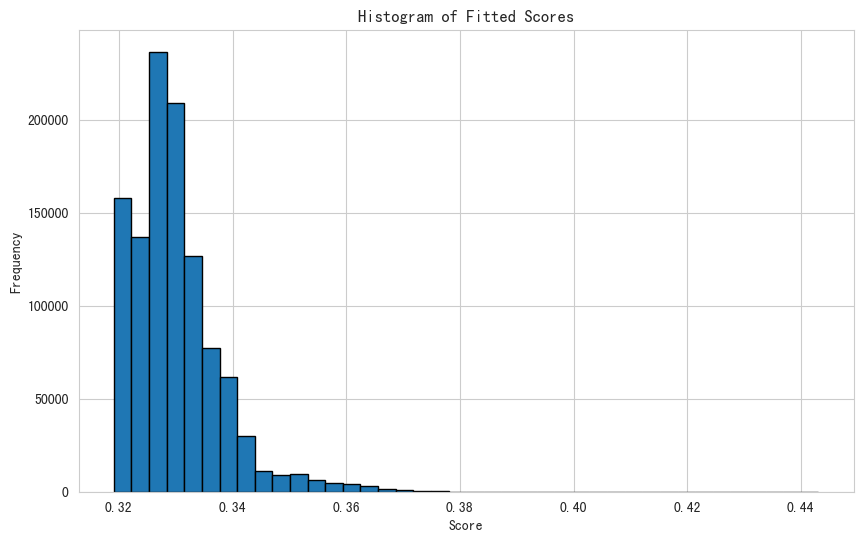

In [81]:
plt.figure(figsize=(10, 6))
plt.hist(df_feas_all['prob_lgb'], bins=40, edgecolor='black')
plt.title('Histogram of Fitted Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

In [142]:
pred_fea = 'prob_lgb'
df_feas_all['score_test'] = df_feas_all[pred_fea].apply(lambda x: Prob2Score(x, basePoint=350, PDO=50) if pd.notnull(x) else x)
min_score = math.floor(df_feas_all['score_test'].min())
max_score = math.ceil(df_feas_all['score_test'].max())
min_score, max_score

(366, 405)

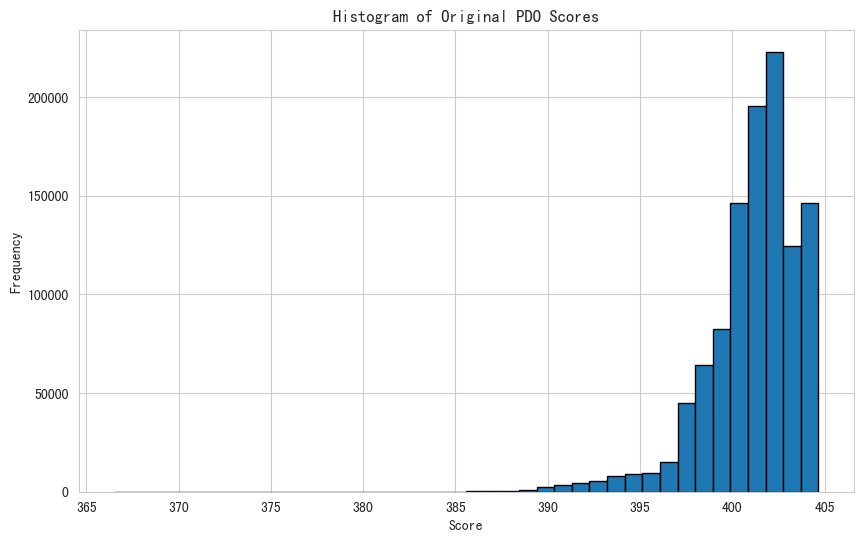

In [143]:
plt.figure(figsize=(10, 6))
plt.hist(df_feas_all['score_test'].dropna(), bins=40, edgecolor='black')
plt.title('Histogram of Original PDO Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

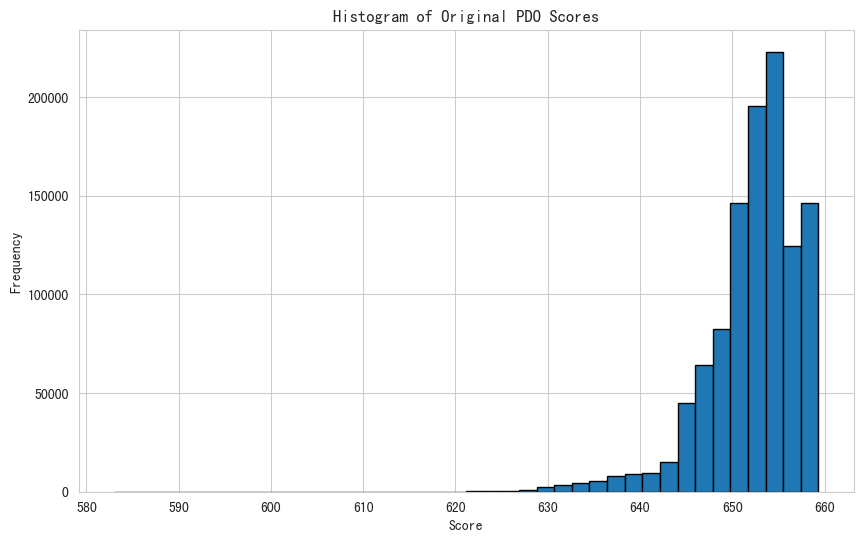

(582, 660)

In [148]:
pred_fea = 'prob_lgb'
df_feas_all['score_test'] = df_feas_all[pred_fea].apply(lambda x: Prob2Score(x, basePoint=550, PDO=100) if pd.notnull(x) else x)
min_score = math.floor(df_feas_all['score_test'].min())
max_score = math.ceil(df_feas_all['score_test'].max())
plt.figure(figsize=(10, 6))
plt.hist(df_feas_all['score_test'].dropna(), bins=40, edgecolor='black')
plt.title('Histogram of Original PDO Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()
min_score, max_score

In [150]:
min_score, max_score

(582, 660)

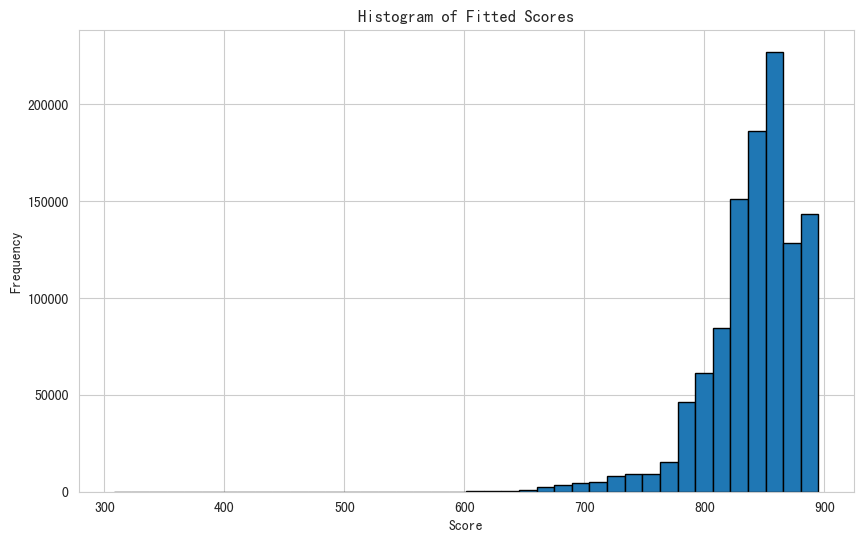

In [149]:
df_feas_all['fit_score_lgb'] = df_feas_all[pred_fea].apply(lambda x: AdjustScore(x, min_score, max_score, basePoint=550, PDO=100))
plt.figure(figsize=(10, 6))
plt.hist(df_feas_all['fit_score_lgb'], bins=40, edgecolor='black')
plt.title('Histogram of Fitted Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

In [136]:
pred_fea = 'prob_lgb'
df_feas_all['score_test'] = df_feas_all[pred_fea].apply(lambda x: Prob2Score(x, basePoint=450, PDO=150) if pd.notnull(x) else x)
min_score = math.floor(df_feas_all['score_test'].min())
max_score = math.ceil(df_feas_all['score_test'].max())
min_score, max_score

(499, 615)

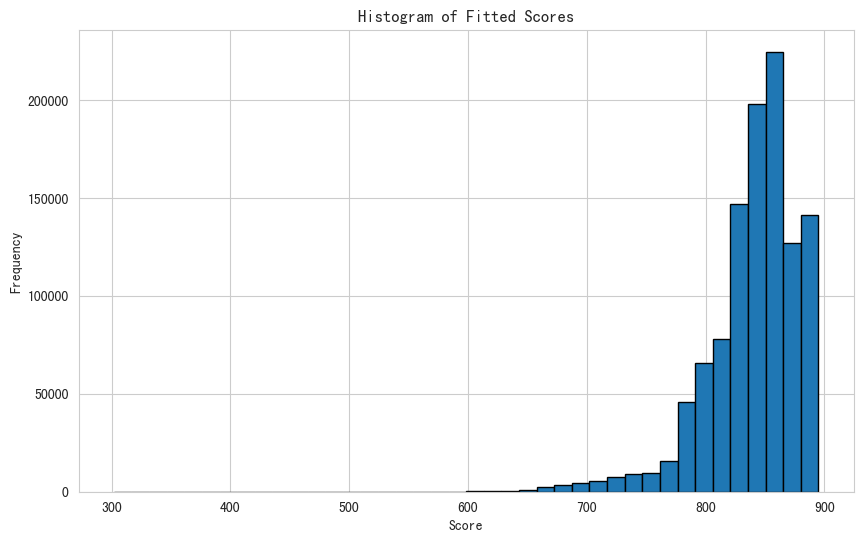

In [137]:
df_feas_all['fit_score_lgb'] = df_feas_all[pred_fea].apply(lambda x: AdjustScore(x, min_score, max_score, basePoint=450, PDO=150))
plt.figure(figsize=(10, 6))
plt.hist(df_feas_all['fit_score_lgb'], bins=40, edgecolor='black')
plt.title('Histogram of Fitted Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

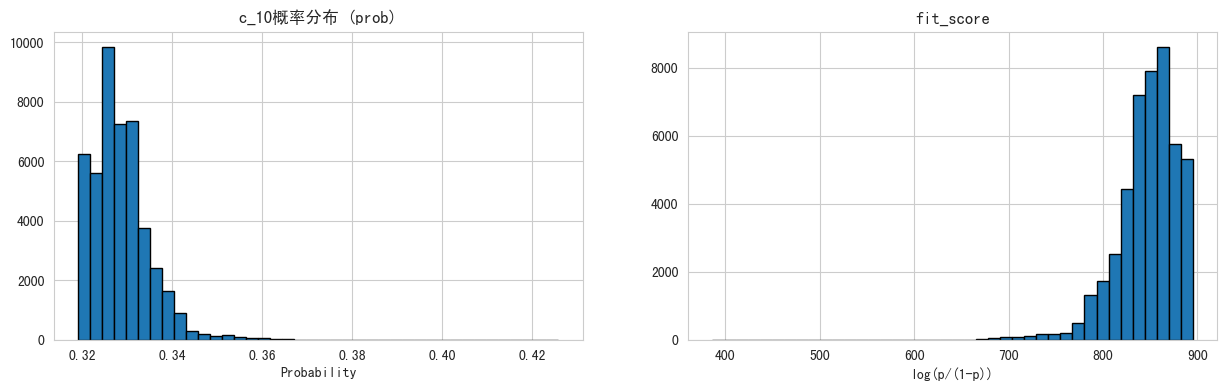

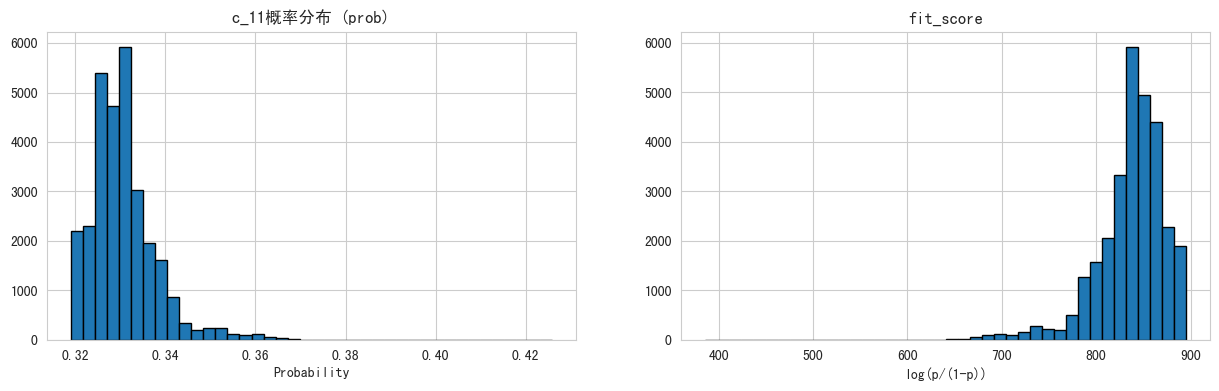

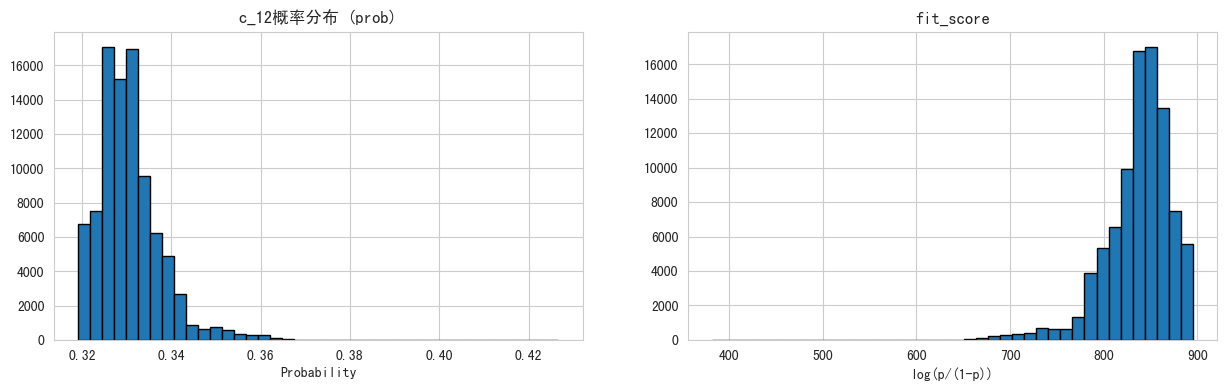

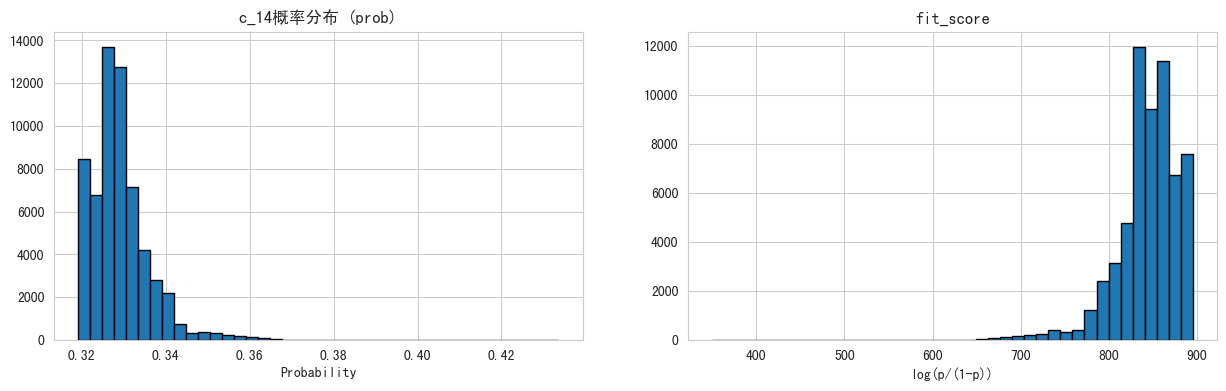

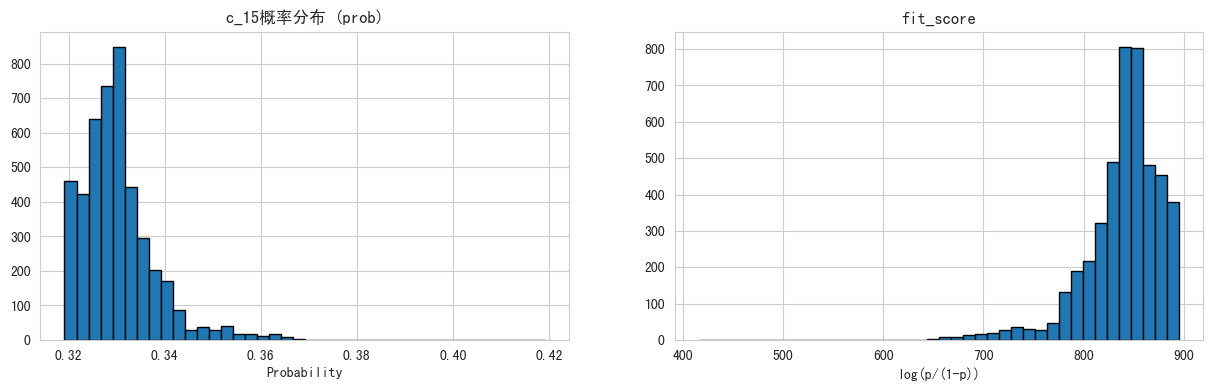

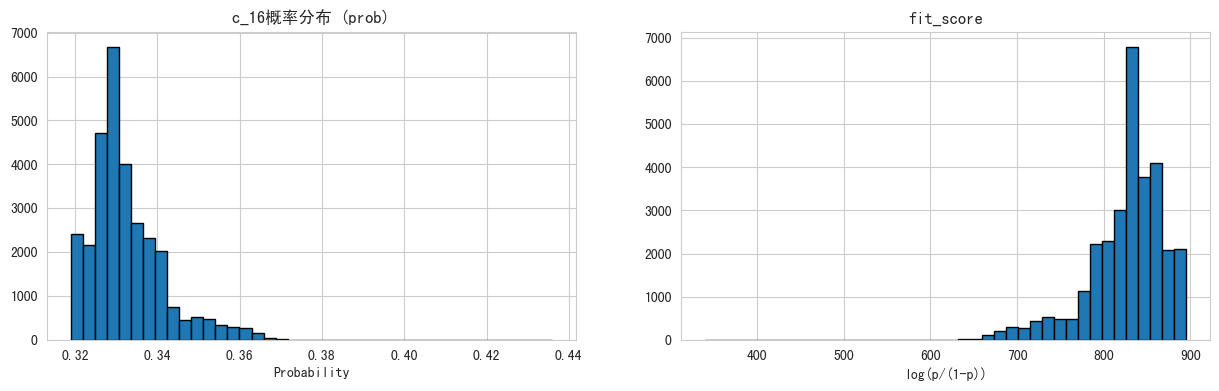

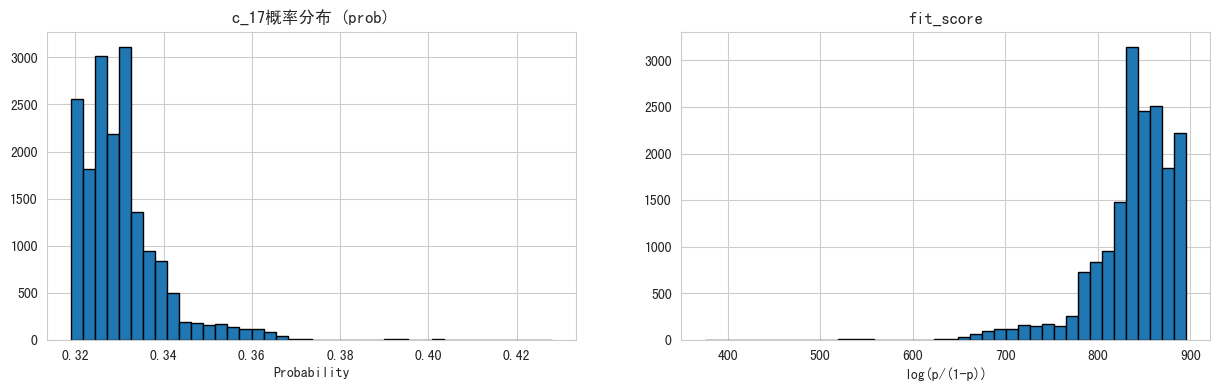

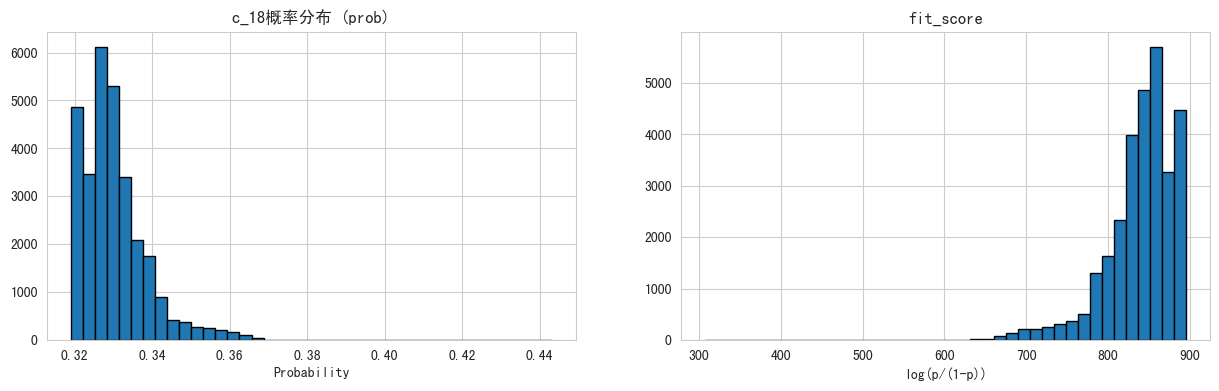

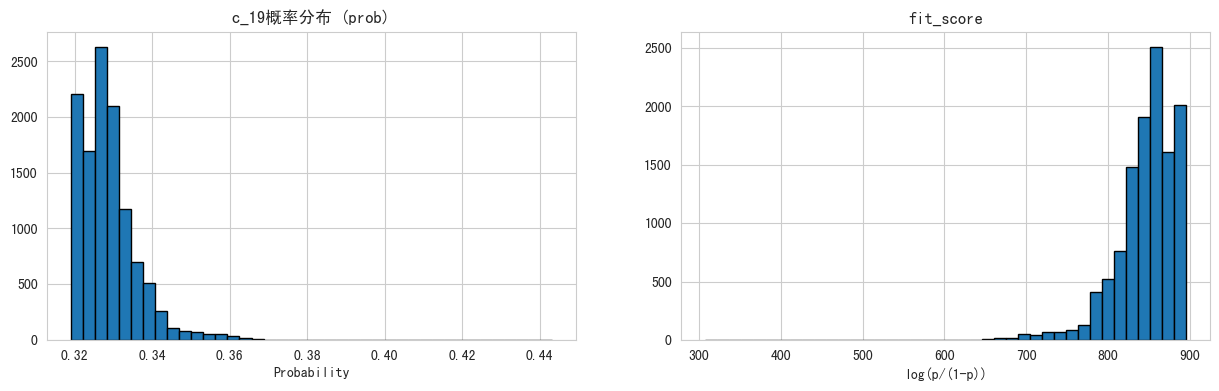

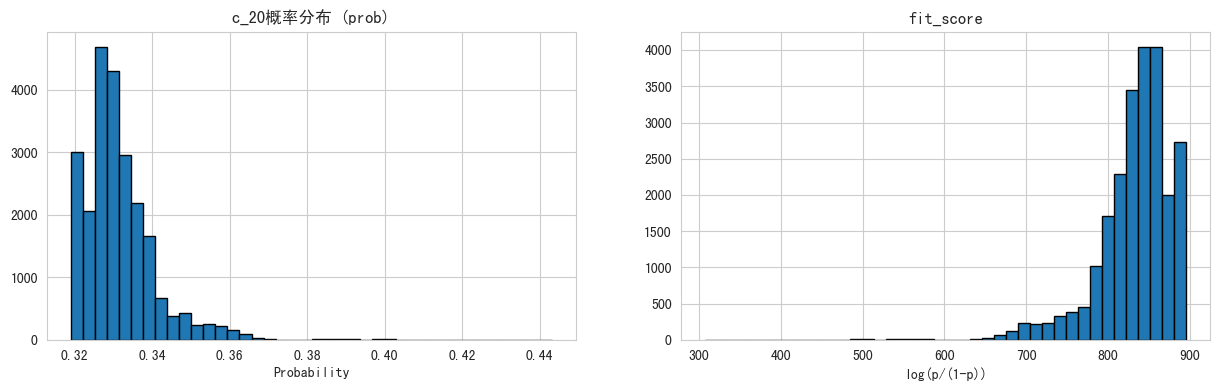

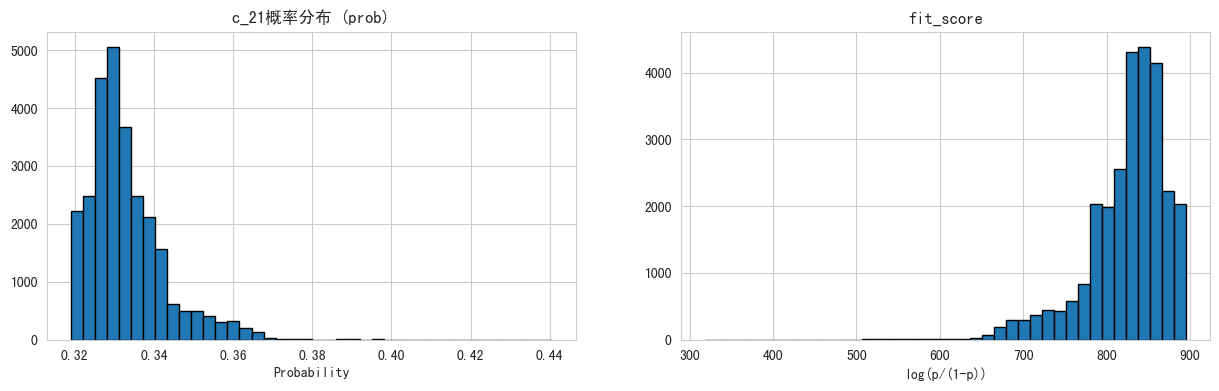

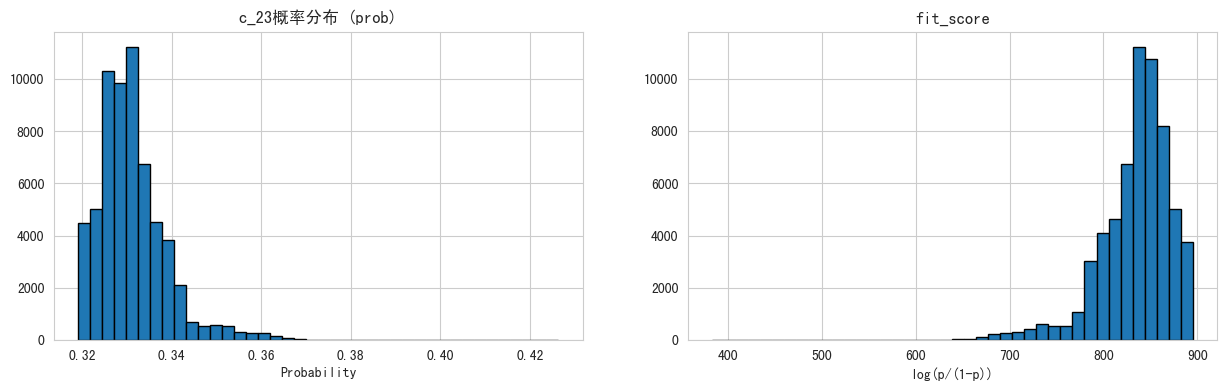

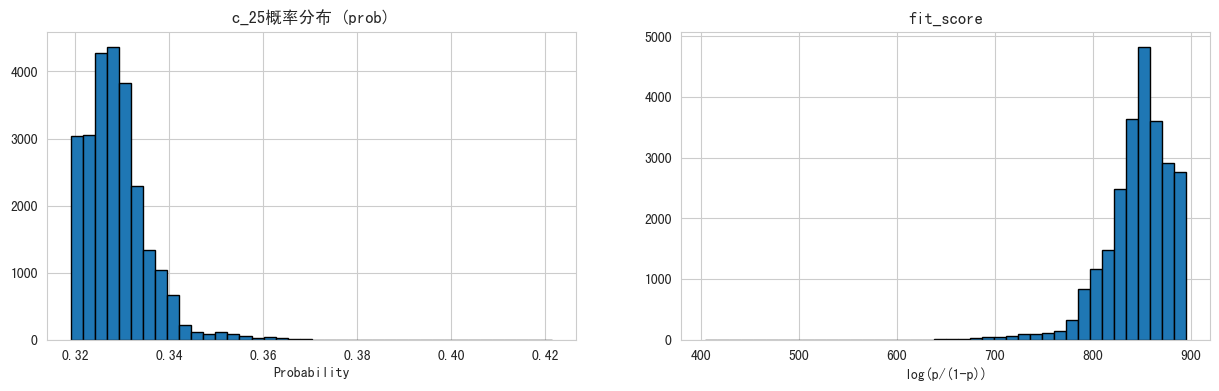

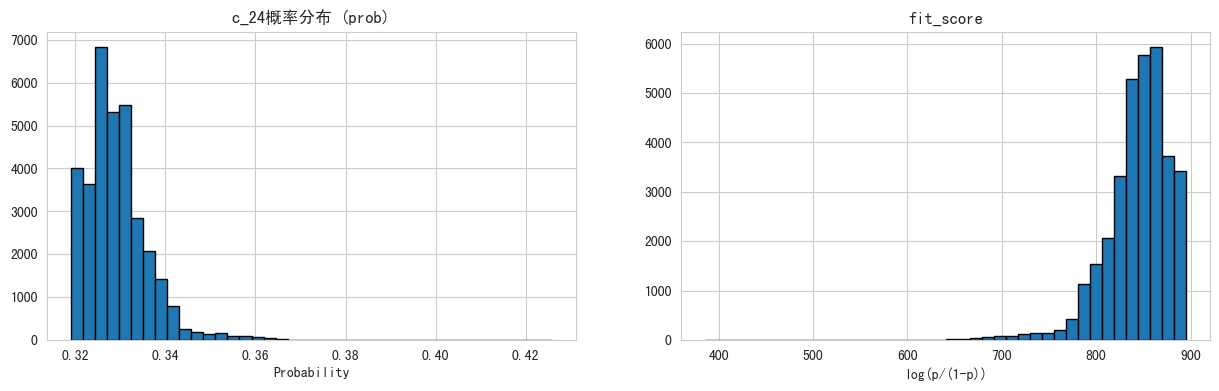

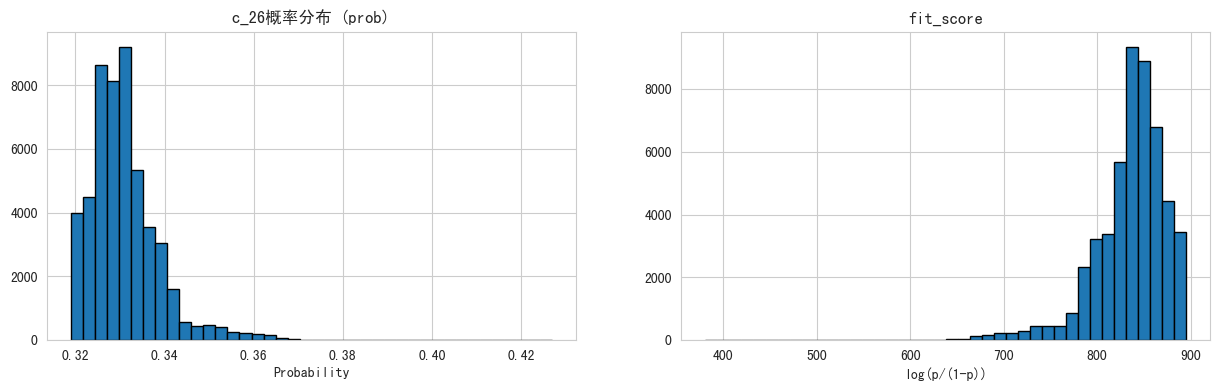

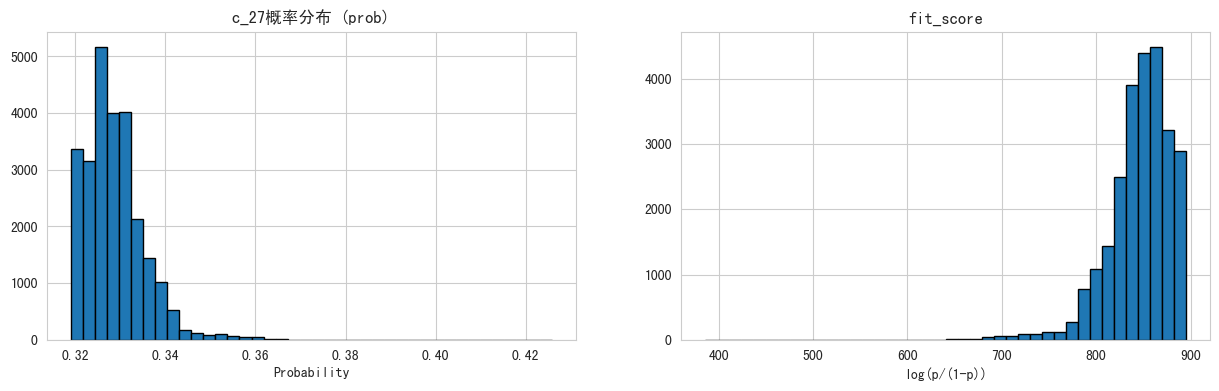

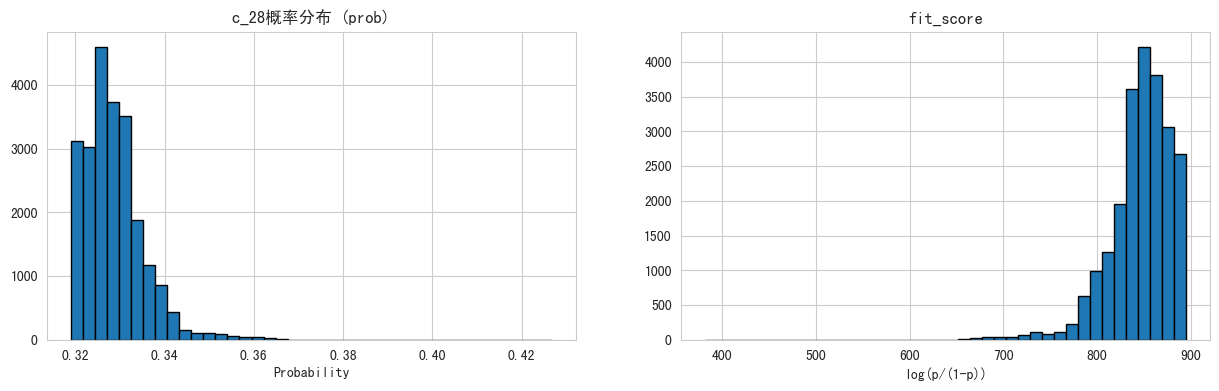

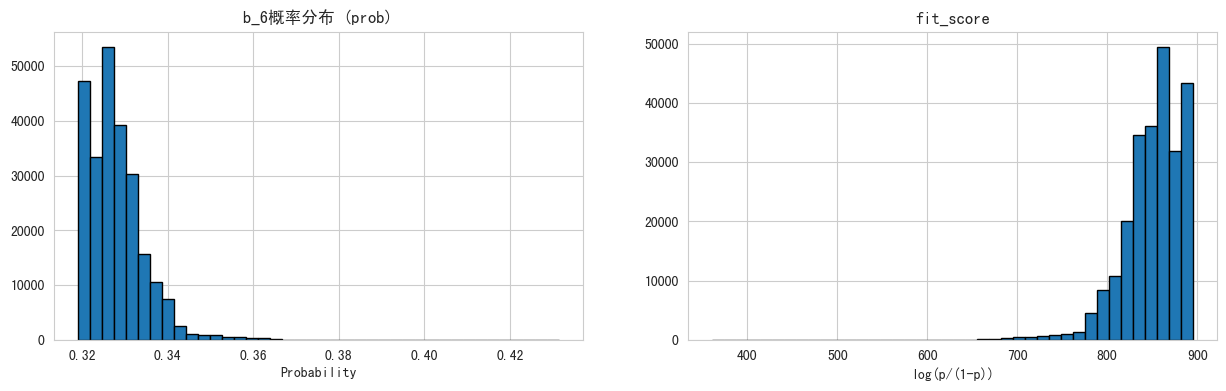

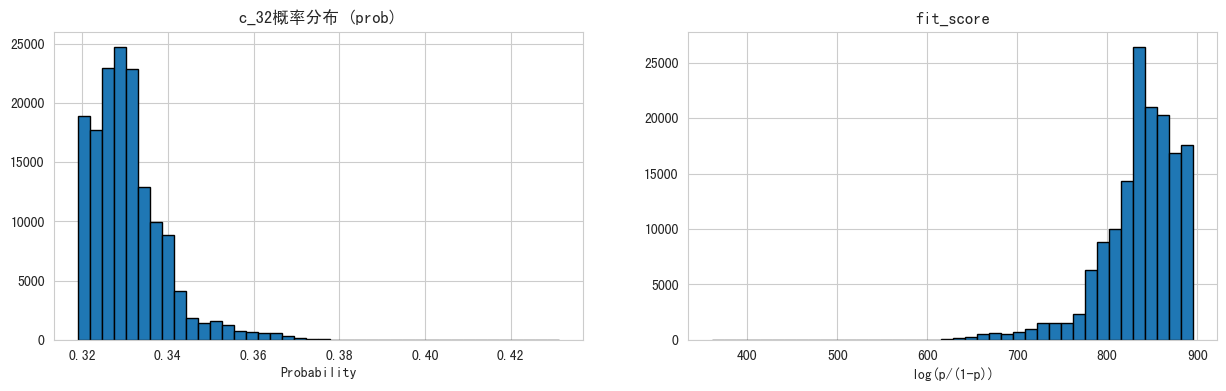

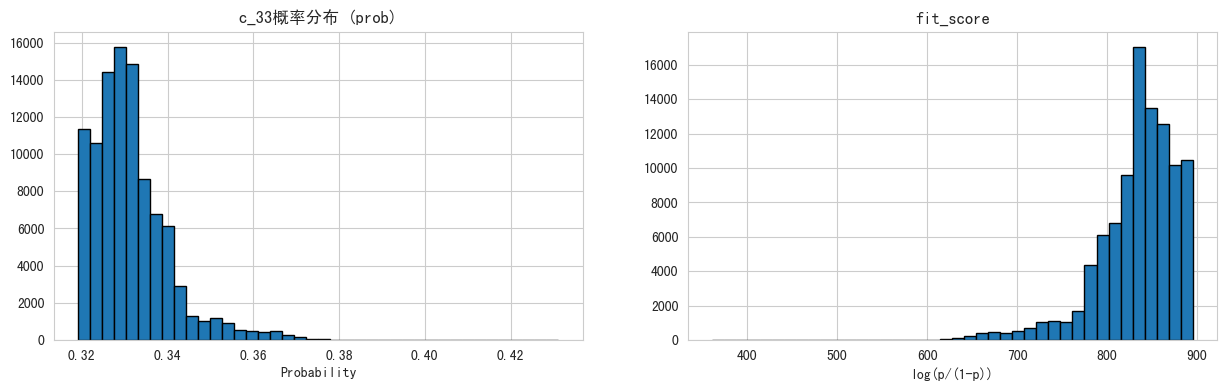

In [90]:
for partner in df_feas_all['partner_code'].unique():
    df_partner = df_feas_all[df_feas_all['partner_code'] == partner]

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # 原始概率分布
    axes[0].hist(df_partner['prob_lgb'].dropna(), bins=40, edgecolor='black')
    axes[0].set_title(f'{partner}概率分布 (prob)')
    axes[0].set_xlabel('Probability')

    # logit 尺度 (log-odds)
    axes[1].hist(df_partner['fit_score'].dropna(), bins=40, edgecolor='black')
    axes[1].set_title('fit_score')
    axes[1].set_xlabel('log(p/(1-p))')

## lr

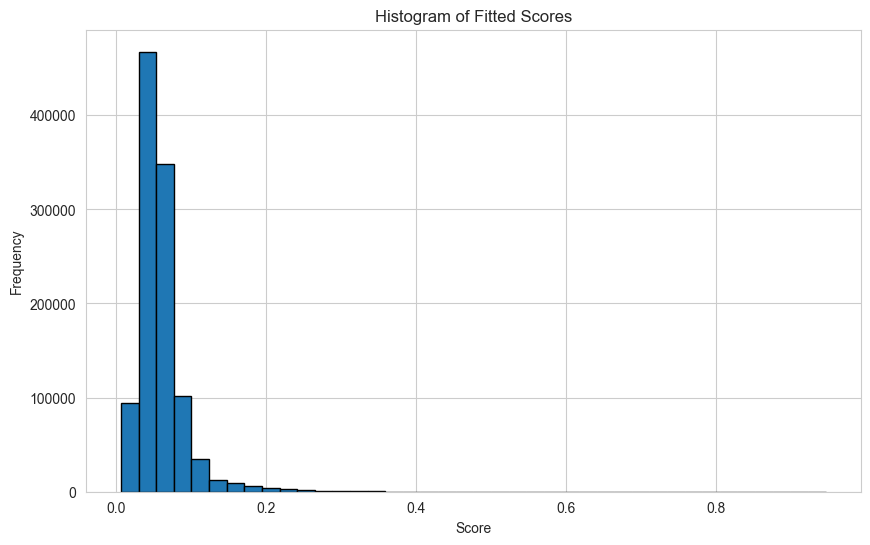

In [28]:
plt.figure(figsize=(10, 6))
plt.hist(df_feas_all['lr_weight_ens_sam_b6'], bins=40, edgecolor='black')
plt.title('Histogram of Fitted Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

In [29]:
pred_fea = 'lr_weight_ens_sam_b6'
df_feas_all['lr_score_test'] = df_feas_all[pred_fea].apply(lambda x: Prob2Score(x, basePoint=800, PDO=100) if pd.notnull(x) else x)
min_score = math.floor(df_feas_all['lr_score_test'].min())
max_score = math.ceil(df_feas_all['lr_score_test'].max())
min_score, max_score

(387, 1511)

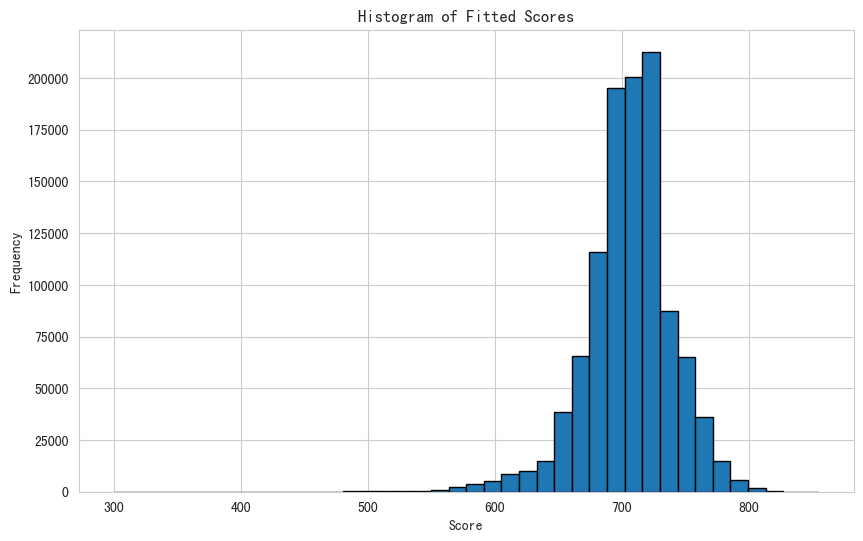

In [125]:
df_feas_all['fit_score_lr'] = df_feas_all[pred_fea].apply(lambda x: AdjustScore(x, 400, 1600, basePoint=800, PDO=100))
plt.figure(figsize=(10, 6))
plt.hist(df_feas_all['fit_score_lr'], bins=40, edgecolor='black')
plt.title('Histogram of Fitted Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

In [1]:
df_feas_all['fit_score_lr'] = df_feas_all[pred_fea].apply(lambda x: AdjustScore(x, 790, 1500, basePoint=800, PDO=100))
plt.figure(figsize=(10, 6))
plt.hist(df_feas_all['fit_score_lr'], bins=30, edgecolor='black')
plt.title('Histogram of Fitted Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

NameError: name 'df_feas_all' is not defined

In [ ]:

fig, ax = plt.subplots(figsize=(10, 6))
counts, bins, patches = ax.hist(df_data[(df_data['partner_code']!='b_21') & (df_data['mid_sample_type'].isin(['1-train','2-ensemble','3-oos']))]['a077_6-2_score'], bins=40, edgecolor='black')
total = counts.sum()
for count, patch in zip(counts, patches):
    percentage = count / total * 100
    if count > 0:
        ax.text(patch.get_x() + patch.get_width() / 2, patch.get_height(),
                f'{percentage:.1f}%', ha='center', va='bottom', fontsize=8)
plt.title('Histogram of Fitted Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [113]:
1

1

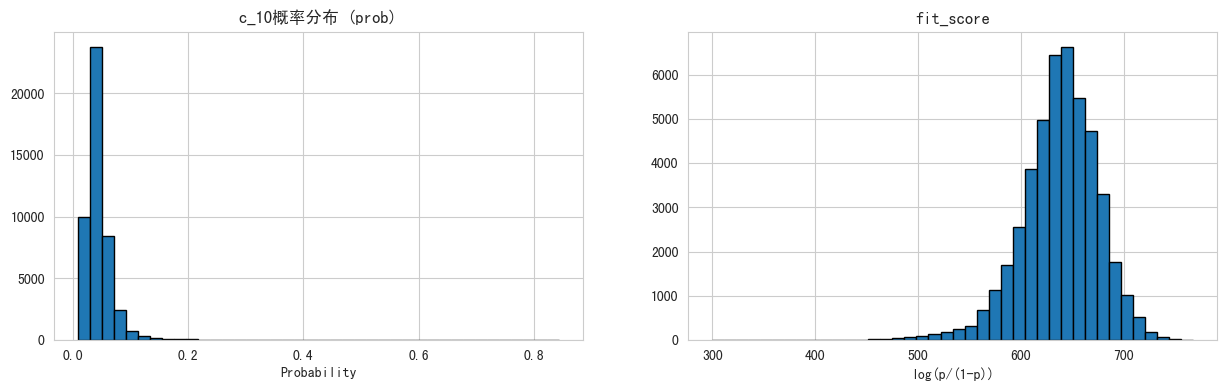

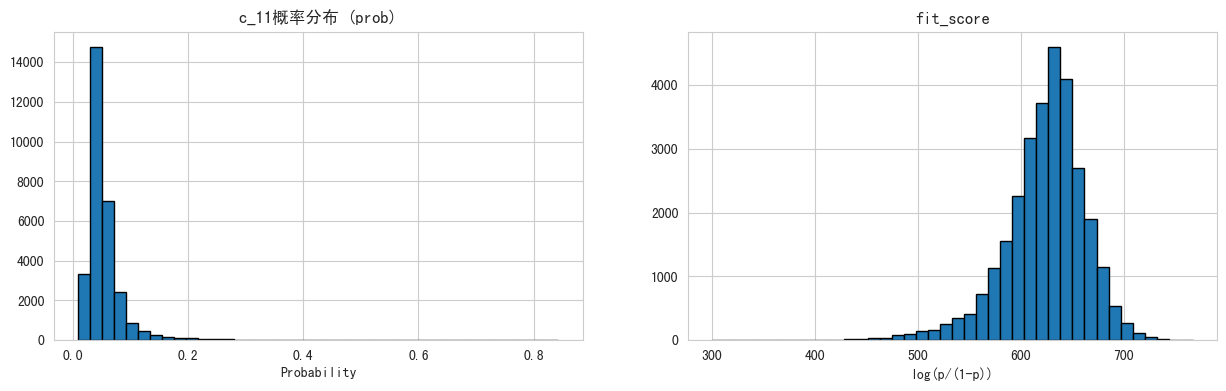

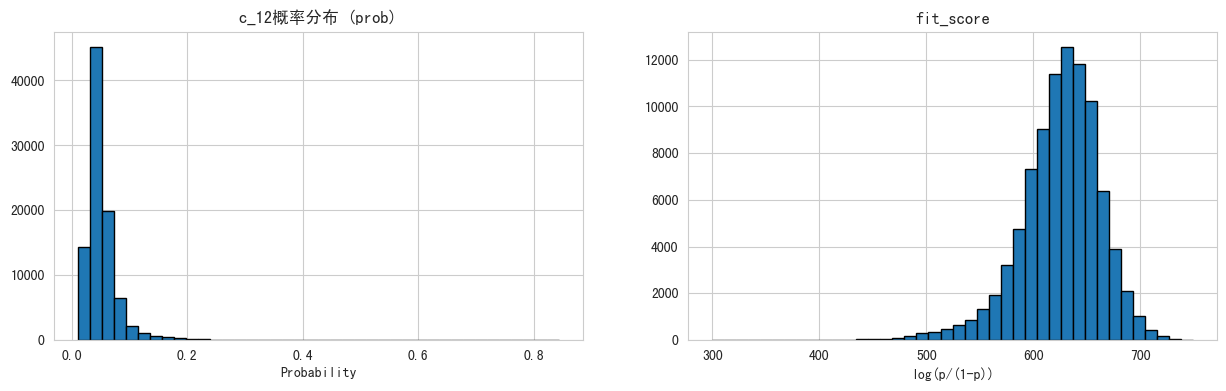

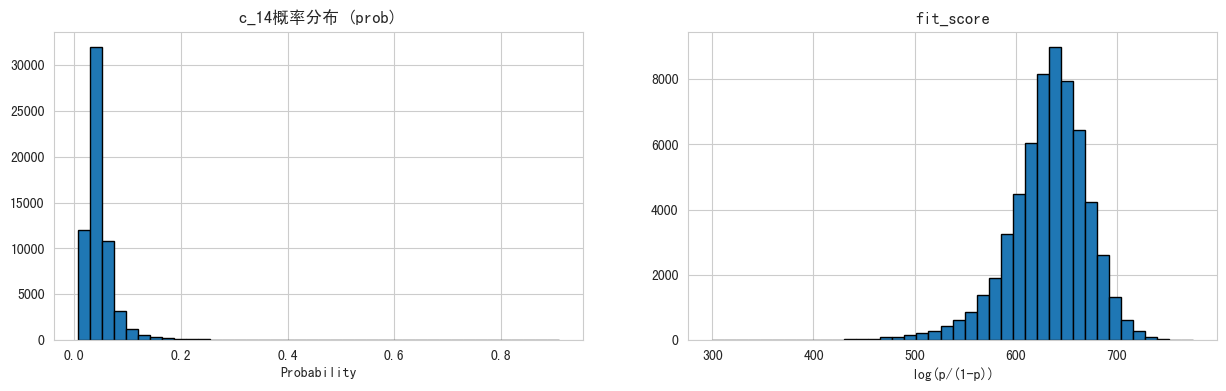

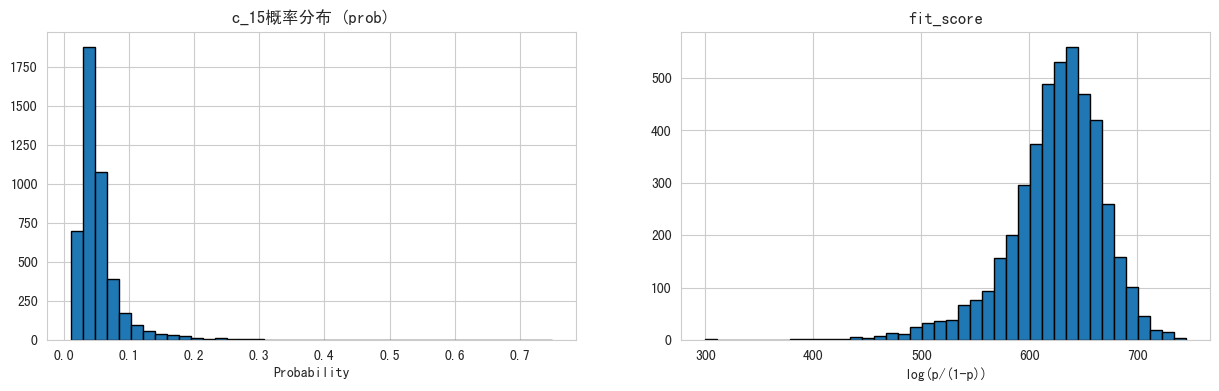

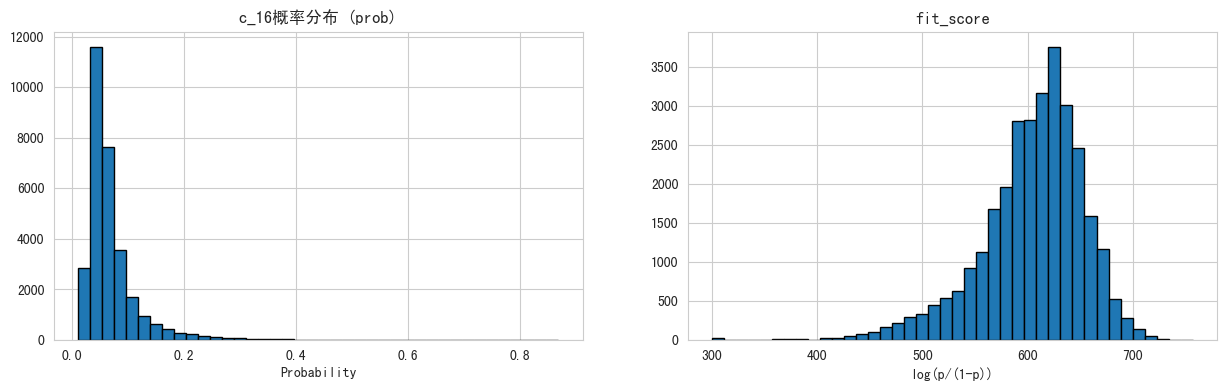

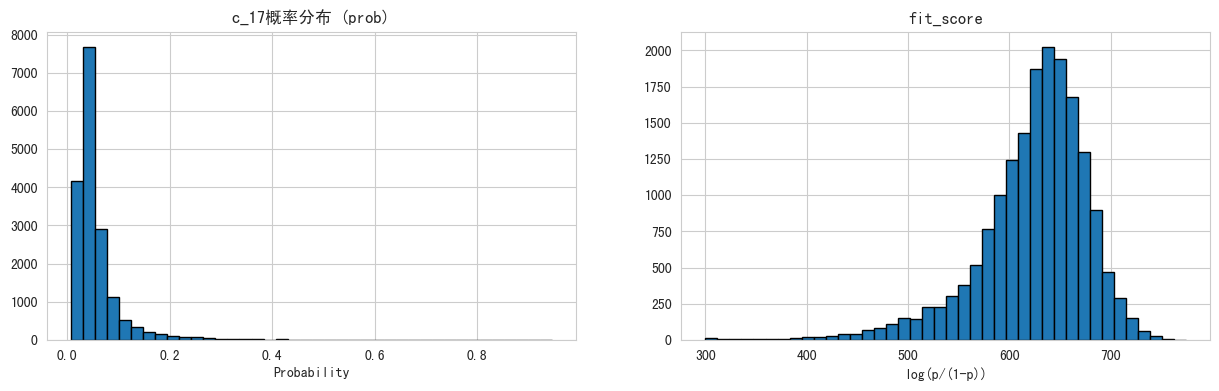

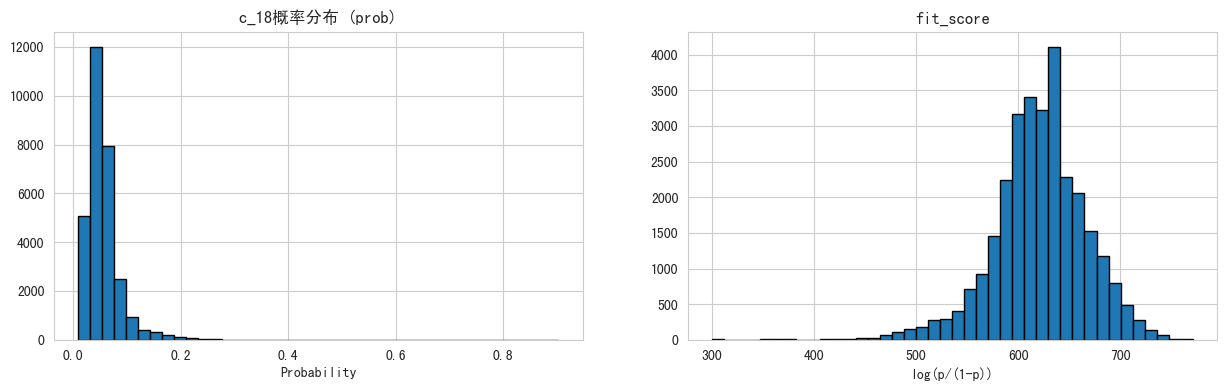

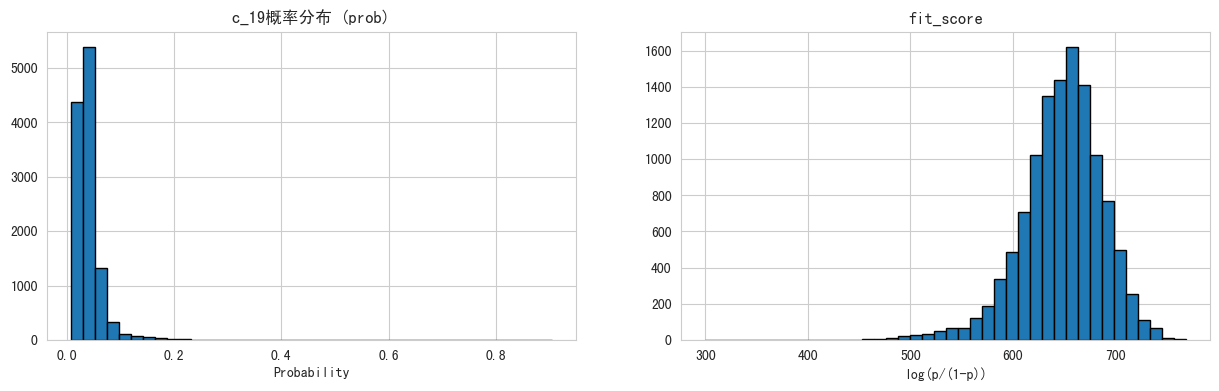

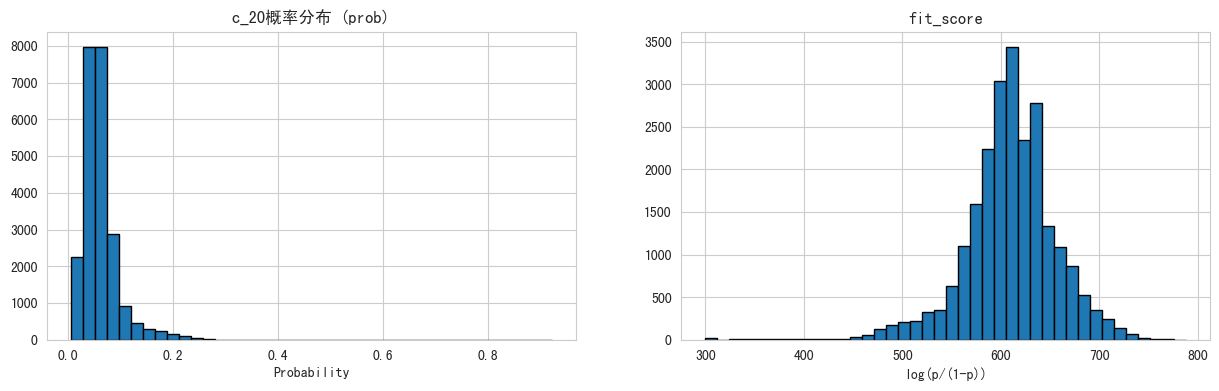

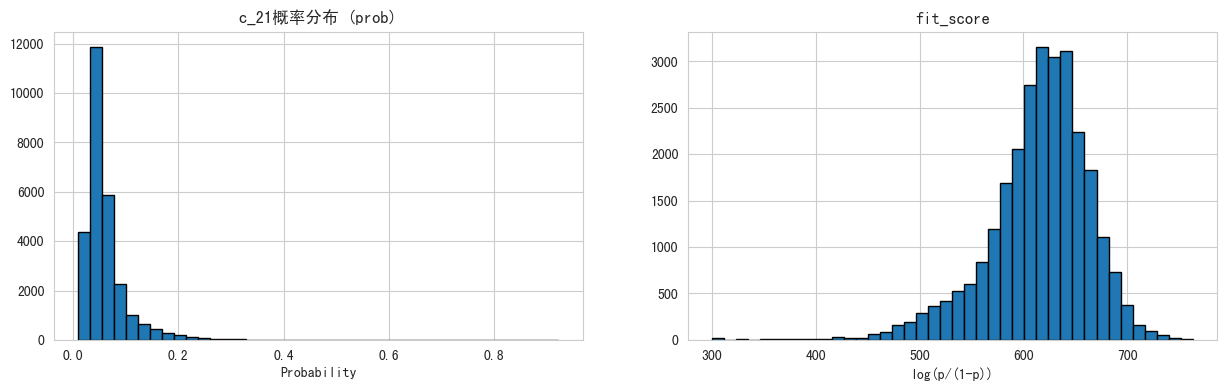

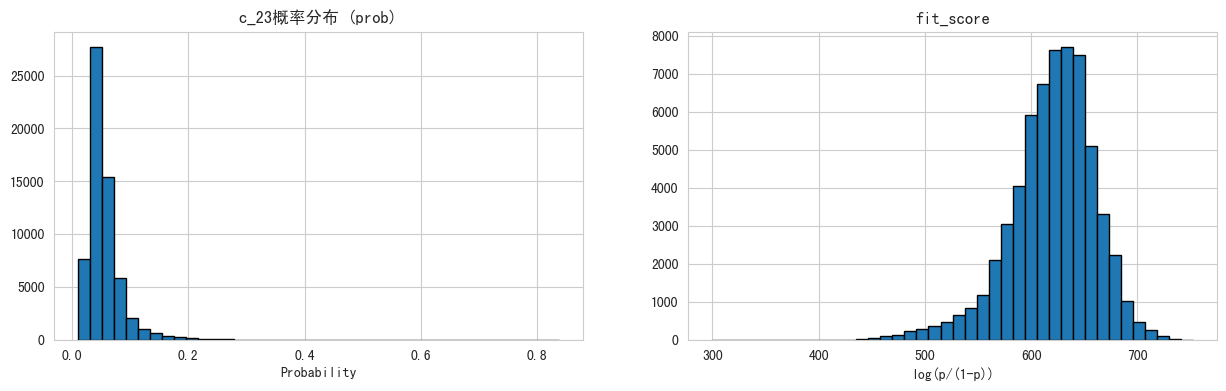

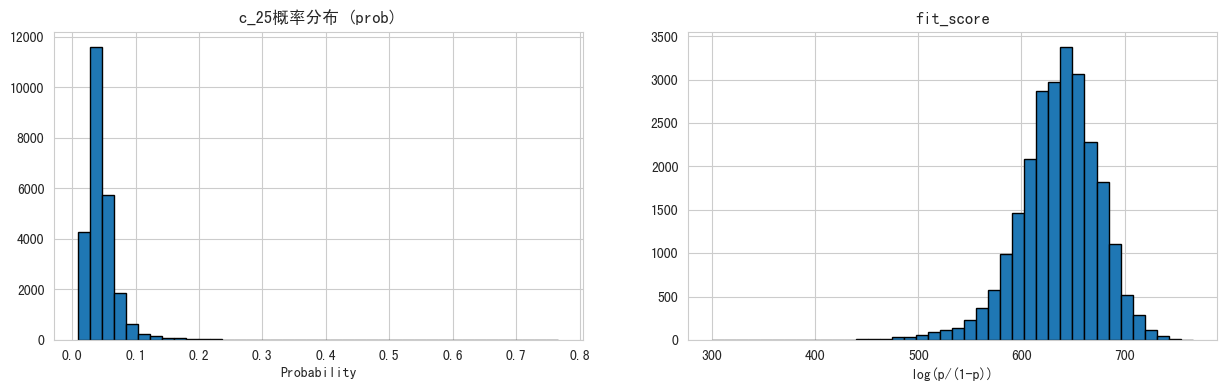

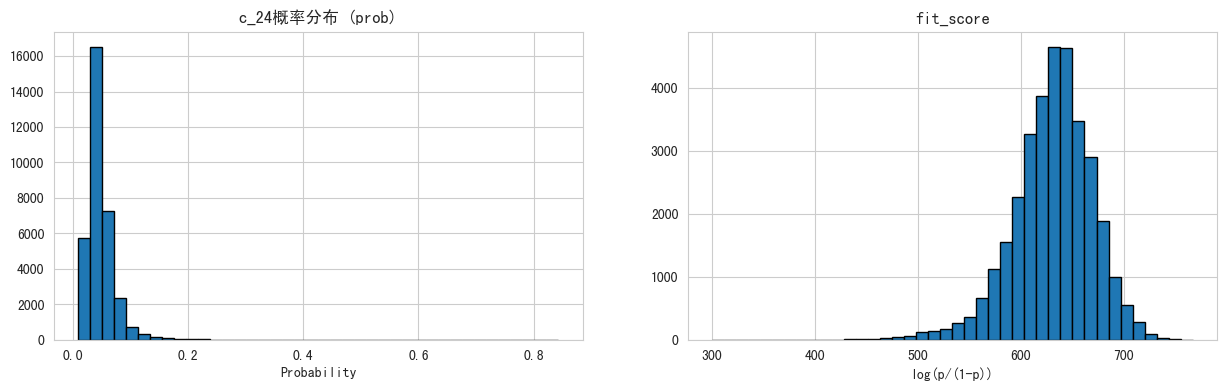

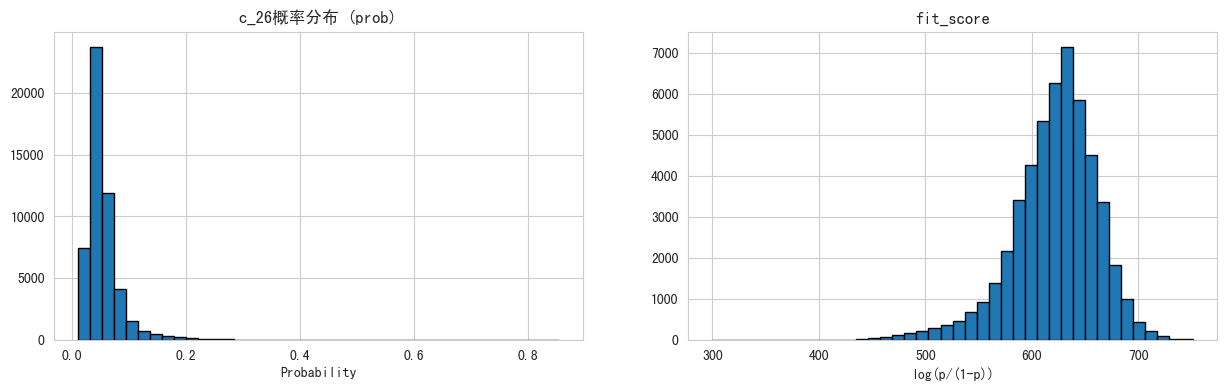

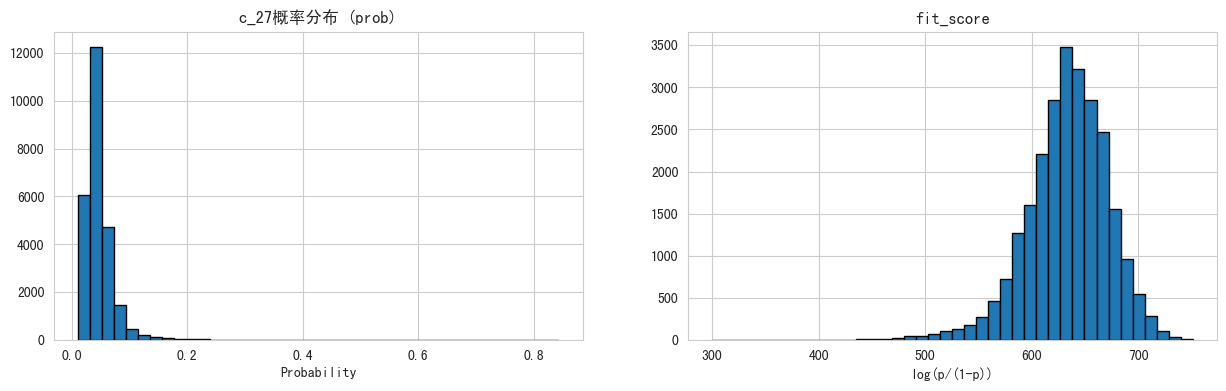

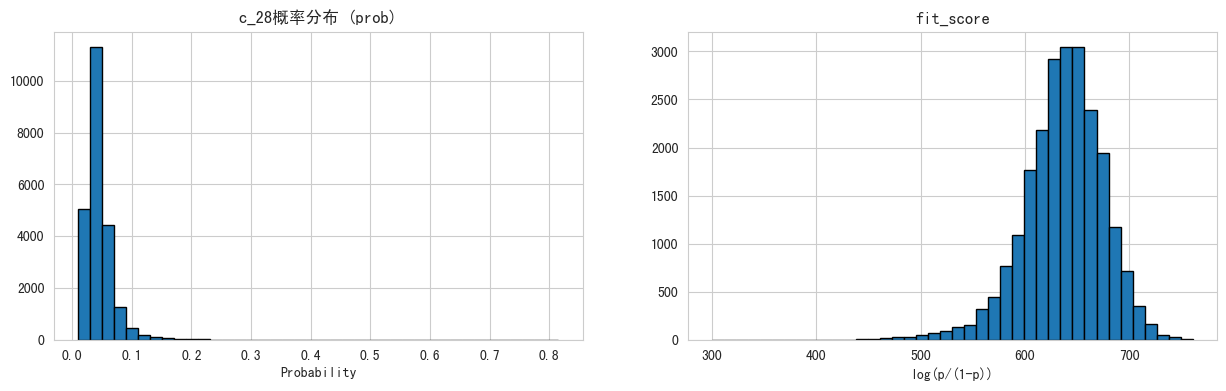

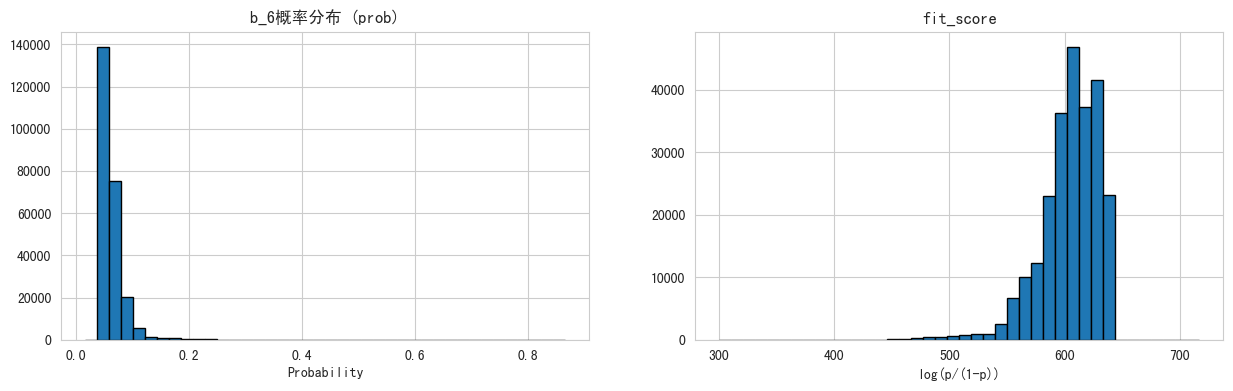

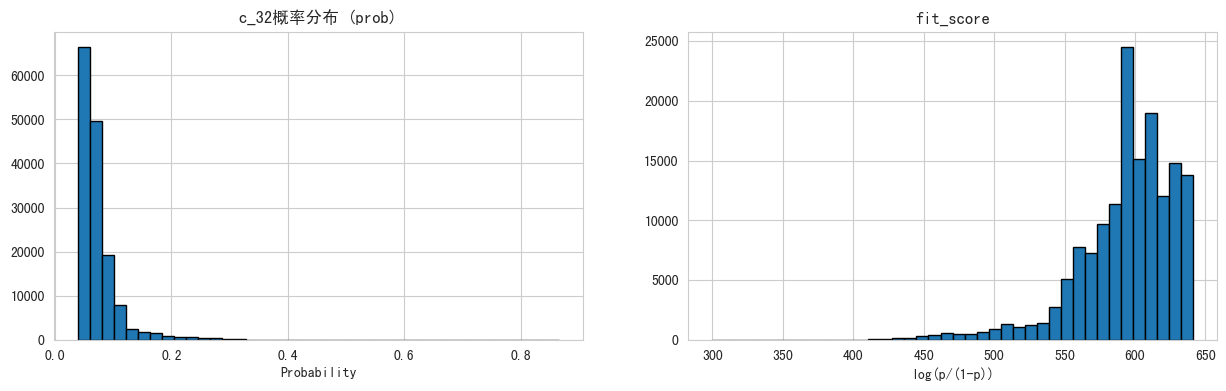

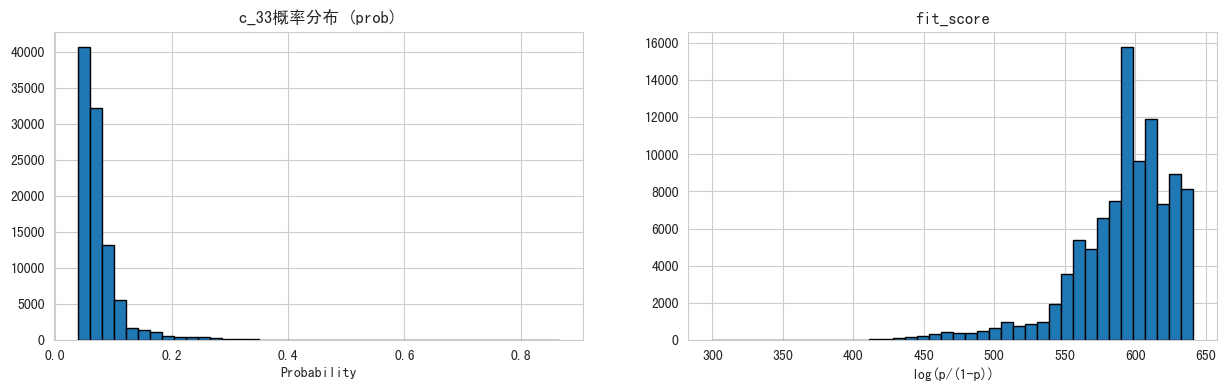

In [111]:
for partner in df_feas_all['partner_code'].unique():
    df_partner = df_feas_all[df_feas_all['partner_code'] == partner]

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # 原始概率分布
    axes[0].hist(df_partner['lr_weight_ens_sam_b6'].dropna(), bins=40, edgecolor='black')
    axes[0].set_title(f'{partner}概率分布 (prob)')
    axes[0].set_xlabel('Probability')

    # logit 尺度 (log-odds)
    axes[1].hist(df_partner['fit_score_lr'].dropna(), bins=40, edgecolor='black')
    axes[1].set_title('fit_score')
    axes[1].set_xlabel('log(p/(1-p))')

In [112]:
df_feas_all.to_csv('df_feas_all_with_prob.csv', index=False)

In [127]:
df_feas_all.columns

Index(['serie_no', 'test_id', 'apply_date', 'hce1', 'hce10', 'hce11', 'hce12',
       'hce13', 'hce14', 'hce15',
       ...
       '蜜蜂分_高利率版6_2_proba_trans', 'prob_lgb_fill', 'prob_lgb_valid',
       'prob_lgb_trans', 'lr_weight_ens_sam_b6', 'score_test', 'fit_score',
       'fit_score_lgb', 'lr_score_test', 'fit_score_lr'],
      dtype='object', length=371)

In [129]:
df_feas_all.drop(columns=['serie_no','partner_name', 'pric_type_code', 'high_sample_type', 'pric_type_desc',
       '蜜蜂分_高利率版5_2_proba','蜜蜂分_高利率版7_2_proba',
       'part_sample_code', 'prob_lgb_all_features', 'prob_lgb_no_zero',
       'prob_diff_no_zero_minus_all','蜜蜂分_高利率版6_2_proba_fill',
       '蜜蜂分_高利率版6_2_proba_valid', '蜜蜂分_高利率版6_2_proba_trans', 'prob_lgb_fill',
       'prob_lgb_valid', 'prob_lgb_trans',
       'score_test', 'fit_score', 'fit_score_lgb', 'lr_score_test',
       'flag',
       'partner_code'],inplace=True)

In [ ]:
df_feas_all.to_csv('/Users/mayongzhi/Job/Job_xyd/code/测试V4+embeding/部署/lrdf_feas_all_with_prob.csv', index=False)

In [ ]:
model_lr.coef_,model_lr.intercept_

(array([[ 0.89209806,  1.27202813, 10.48431108,  0.        ]]),
 array([4.76268619]))

In [30]:
model_lr.coef_,model_lr.intercept_

(array([[ 0.89257095,  1.27228985, 10.48985868,  7.38644473]]),
 array([-2.62072796]))

In [32]:
valid_lr = pd.read_csv('部署/lr/valid_data.csv')
valid_lr.head()

,test_id,hce1,hce10,hce11,hce12,hce13,hce14,hce15,hce16,hce17,...,hxe77,hxe78,hxe79,hxe8,hxe80,hxe9,蜜蜂分_高利率版6_2_proba,prob_a080,prob_b072,score_b072
0,5805962,22.0,1.0,1.0,1.0,24.0,1.0,1.0,1.0,22.0,...,0.0,0.0,0.0,0.0,0.0,0.163347,NaN,0.336297,0.085883,597
1,5710757,1.0,9.0,21.0,18.0,1.0,20.0,20.0,19.0,14.0,...,0.0,0.0,0.0,0.0,0.0,0.472044,NaN,0.325259,0.052761,661
2,5586170,21.0,1.0,1.0,1.0,24.0,1.0,1.0,1.0,20.0,...,0.0,0.0,0.0,0.0,0.0,0.142847,NaN,0.342361,0.110921,562
3,4623099,20.0,1.0,15.0,1.0,20.0,13.0,11.0,8.0,17.0,...,0.0,0.0,0.0,0.0,0.0,0.565337,NaN,0.319782,0.041069,693
4,5794840,19.0,1.0,6.0,1.0,22.0,1.0,7.0,1.0,16.0,...,0.0,0.0,0.0,0.0,0.0,0.437262,NaN,0.326892,0.056793,651


In [37]:
# ym_feas 全为空 则prob_a080 为空，而不是0
valid_lr['prob_a080'] = valid_lr.apply(lambda x: np.nan if x[ym_feas].isnull().all() else x['prob_a080'], axis=1)
valid_lr.head()


,test_id,hce1,hce10,hce11,hce12,hce13,hce14,hce15,hce16,hce17,...,hxe77,hxe78,hxe79,hxe8,hxe80,hxe9,蜜蜂分_高利率版6_2_proba,prob_a080,prob_b072,score_b072
0,5805962,22.0,1.0,1.0,1.0,24.0,1.0,1.0,1.0,22.0,...,0.0,0.0,0.0,0.0,0.0,0.163347,NaN,0.336297,0.085883,597
1,5710757,1.0,9.0,21.0,18.0,1.0,20.0,20.0,19.0,14.0,...,0.0,0.0,0.0,0.0,0.0,0.472044,NaN,0.325259,0.052761,661
2,5586170,21.0,1.0,1.0,1.0,24.0,1.0,1.0,1.0,20.0,...,0.0,0.0,0.0,0.0,0.0,0.142847,NaN,0.342361,0.110921,562
3,4623099,20.0,1.0,15.0,1.0,20.0,13.0,11.0,8.0,17.0,...,0.0,0.0,0.0,0.0,0.0,0.565337,NaN,0.319782,0.041069,693
4,5794840,19.0,1.0,6.0,1.0,22.0,1.0,7.0,1.0,16.0,...,0.0,0.0,0.0,0.0,0.0,0.437262,NaN,0.326892,0.056793,651


In [59]:
valid_lr['prob_lgb'] = valid_lr['prob_a080']

In [60]:
sub_probs = ['蜜蜂分_高利率版6_2_proba','prob_lgb']
feas = []
for fea in sub_probs:
    valid_lr[f'{fea}_fill'] = valid_lr[fea].fillna(0)
    valid_lr[f'{fea}_valid'] = valid_lr[f'{fea}_fill'].apply(get_valid_prob)
    valid_lr[f'{fea}_trans'] = valid_lr[f'{fea}_fill'].apply(LogitTransformation)
    feas.append(f'{fea}_trans')
    feas.append(f'{fea}_valid')

In [61]:
valid_lr['prob_b072'] = model_lr.predict_proba(valid_lr[feas])[:,1]

In [62]:
valid_lr['score_b072'] = valid_lr['prob_b072'].apply(lambda x: AdjustScore(x, 790, 1500, basePoint=800, PDO=100))

In [67]:
valid_lr.columns

Index(['test_id', 'hce1', 'hce10', 'hce11', 'hce12', 'hce13', 'hce14', 'hce15',
       'hce16', 'hce17',
       ...
       'hxe77', 'hxe78', 'hxe79', 'hxe8', 'hxe80', 'hxe9', '蜜蜂分_高利率版6_2_proba',
       'prob_a080', 'prob_b072', 'score_b072'],
      dtype='object', length=347)

In [48]:
valid_lr.columns[-25:]

Index(['hxe72', 'hxe73', 'hxe74', 'hxe75', 'hxe76', 'hxe77', 'hxe78', 'hxe79',
       'hxe8', 'hxe80', 'hxe9', '蜜蜂分_高利率版6_2_proba', 'prob_a080', 'prob_b072',
       'score_b072', '蜜蜂分_高利率版6_2_proba_fill', '蜜蜂分_高利率版6_2_proba_valid',
       '蜜蜂分_高利率版6_2_proba_trans', 'prob_a080_fill', 'prob_a080_valid',
       'prob_a080_trans', 'prob_lgb', 'prob_lgb_fill', 'prob_lgb_valid',
       'prob_lgb_trans'],
      dtype='object')

In [64]:
valid_lr.drop(columns=['蜜蜂分_高利率版6_2_proba_fill',
       '蜜蜂分_高利率版6_2_proba_valid', '蜜蜂分_高利率版6_2_proba_trans', 'prob_lgb',
       'prob_lgb_fill', 'prob_lgb_valid', 'prob_lgb_trans'],inplace=True)

In [65]:

valid_lr.loc[(valid_lr['prob_a080'].isna()) & (valid_lr['蜜蜂分_高利率版6_2_proba'].isna()), 'score_b072'] = 0

In [66]:
valid_lr.to_csv('部署/lr/valid_data.csv')